# 1. Polazni pregled i struktura skupa podataka

## 1.1. Učitavanje i dimenzije skupa podataka

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_sas("LLCP2020.XPT", format="xport", encoding=None)

print("Broj redova:", df.shape[0])
print("Broj kolona:", df.shape[1])

Broj redova: 401958
Broj kolona: 279


## 1.2. Prikaz prvih pet zapisa

In [3]:
display(df.head(5))

df.head(5).to_csv("prvih_5_zapisa.csv", index=False)

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_RFPSA23,_CLNSCPY,_SGMSCPY,_SGMS10Y,_RFBLDS4,_STOLDNA,_VIRCOLN,_SBONTIM,_CRCREC1,_AIDTST4
0,1.0,1.0,b'01042020',b'01',b'04',b'2020',1100.0,b'2020000001',2.020000e+09,1.0,...,NaN,1.0,3.0,3.0,3.0,3.0,3.0,3.0,1.0,1.0
1,1.0,1.0,b'02072020',b'02',b'07',b'2020',1200.0,b'2020000002',2.020000e+09,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN
2,1.0,1.0,b'01232020',b'01',b'23',b'2020',1100.0,b'2020000003',2.020000e+09,1.0,...,NaN,1.0,3.0,3.0,3.0,3.0,3.0,3.0,1.0,2.0
3,1.0,1.0,b'01092020',b'01',b'09',b'2020',1100.0,b'2020000004',2.020000e+09,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0
4,1.0,1.0,b'01042020',b'01',b'04',b'2020',1100.0,b'2020000005',2.020000e+09,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0


## 1.3. Tehnički tipovi i jedinstvene vrijednosti varijabli

In [4]:
pregled = pd.DataFrame({
    "Naziv varijable": df.columns,
    "Tehnicki tip": df.dtypes.astype(str).values,
    "Broj jedinstvenih vrijednosti": df.nunique().values
})

display(pregled)

pregled.to_csv("pregled_varijabli.csv", index=False)

display(df.dtypes.value_counts().to_frame("Broj varijabli"))

print("Broj konstantnih varijabli:", (df.nunique() == 1).sum())
print("Broj potpuno praznih varijabli:", (df.nunique() == 0).sum())

,Naziv varijable,Tehnicki tip,Broj jedinstvenih vrijednosti
0,_STATE,float64,53
1,FMONTH,float64,12
2,IDATE,object,439
3,IMONTH,object,12
4,IDAY,object,31
...,...,...,...
274,_STOLDNA,float64,3
275,_VIRCOLN,float64,3
276,_SBONTIM,float64,3
277,_CRCREC1,float64,3


,Broj varijabli
float64,274
object,5


Broj konstantnih varijabli: 9
Broj potpuno praznih varijabli: 3


## 1.4. Sažeti pregled i značenje varijabli

In [5]:
odabrane_varijable = [
    "_STATE", "IDATE", "SEQNO", "_PSU",
    "SEXVAR", "_AGE80", "EDUCA", "INCOME2",
    "ADDEPEV3", "ACEDEPRS", "ACEDRINK",
    "ACEDRUGS", "ACEPRISN", "ACEDIVRC",
    "ACEPUNCH", "ACEHURT1", "ACESWEAR",
    "ACETOUCH", "ACETTHEM", "ACEHVSEX",
    "CTELENM1", "TOLDCFS"
]

sazeti_pregled = pregled[
    pregled["Naziv varijable"].isin(odabrane_varijable)
]

display(sazeti_pregled)

,Naziv varijable,Tehnicki tip,Broj jedinstvenih vrijednosti
0,_STATE,float64,53
2,IDATE,object,439
7,SEQNO,object,15835
8,_PSU,float64,15835
9,CTELENM1,float64,1
31,SEXVAR,float64,2
51,ADDEPEV3,float64,4
58,EDUCA,float64,7
66,INCOME2,float64,10
130,TOLDCFS,float64,0


## 1.5. Konstantne i gotovo konstantne varijable

In [6]:
konstantne = []

for kolona in df.columns:
    udjeli = df[kolona].value_counts(normalize=True)

    if not udjeli.empty and udjeli.iloc[0] >= 0.95:
        konstantne.append({
            "Varijabla": kolona,
            "Udio najcesce vrijednosti (%)": round(udjeli.iloc[0] * 100, 2),
            "Napomena": "Konstantna" if udjeli.iloc[0] == 1 else "Gotovo konstantna"
        })

konstantne = pd.DataFrame(konstantne)

display(konstantne)

display(konstantne["Napomena"].value_counts().to_frame("Broj varijabli"))

,Varijabla,Udio najcesce vrijednosti (%),Napomena
0,IYEAR,96.98,Gotovo konstantna
1,CTELENM1,100.00,Konstantna
2,PVTRESD1,99.98,Gotovo konstantna
3,COLGHOUS,100.00,Konstantna
4,STATERE1,100.00,Konstantna
5,CELPHONE,100.00,Konstantna
6,LADULT1,99.14,Gotovo konstantna
7,SAFETIME,100.00,Konstantna
8,CTELNUM1,100.00,Konstantna
9,CELLFON5,100.00,Konstantna


,Broj varijabli
Napomena,
Gotovo konstantna,16
Konstantna,9


## 1.6. Provjera jedinstvenosti anketnih zapisa

In [7]:
ponovljeni_identifikatori = df.duplicated(
    subset=["_STATE", "SEQNO"]
).sum()

print("Ukupan broj zapisa:", len(df))

print("Ponovljeni identifikatori:", ponovljeni_identifikatori)

print("Udio ponovljenih identifikatora:",
      round(ponovljeni_identifikatori / len(df) * 100, 2), "%")

Ukupan broj zapisa: 401958
Ponovljeni identifikatori: 0
Udio ponovljenih identifikatora: 0.0 %


# 2. Nedostajući podaci i početna provjera kvaliteta

## 2.1. Pregled nedostajućih vrijednosti

In [8]:
nedostajuci = pd.DataFrame({
    "Varijabla": df.columns,
    "Broj nedostajucih": df.isna().sum().values,
    "Postotak nedostajucih": (
        df.isna().mean() * 100
    ).round(2).values
})

nedostajuci = nedostajuci.sort_values(
    by="Postotak nedostajucih",
    ascending=False
)

display(nedostajuci.head(10))

nedostajuci.to_csv(
    "nedostajuce_vrijednosti.csv",
    index=False
)

print("Broj varijabli bez nedostajucih vrijednosti:",
      (nedostajuci["Broj nedostajucih"] == 0).sum())

print("Broj varijabli s nedostajucim vrijednostima:",
      (nedostajuci["Broj nedostajucih"] > 0).sum())

,Varijabla,Broj nedostajucih,Postotak nedostajucih
130,TOLDCFS,401958,100.00
131,HAVECFS,401958,100.00
132,WORKCFS,401958,100.00
15,COLGSEX,401935,99.99
11,COLGHOUS,401935,99.99
138,MEDSHEPB,401807,99.96
136,HAVEHEPC,401687,99.93
135,PRIRHEPC,401687,99.93
134,TRETHEPC,401687,99.93
178,PCDMDEC1,401540,99.90


Broj varijabli bez nedostajucih vrijednosti: 50
Broj varijabli s nedostajucim vrijednostima: 229


## 2.2. Nedostajući podaci kod varijabli značajnih za temu projekta

,Varijabla,Broj nedostajucih,Postotak nedostajucih
197,ACEHVSEX,273459,68.03
196,ACETTHEM,273360,68.01
195,ACETOUCH,273271,67.98
194,ACESWEAR,273191,67.97
193,ACEHURT1,273103,67.94
192,ACEPUNCH,272990,67.92
191,ACEDIVRC,272915,67.90
190,ACEPRISN,272878,67.89
189,ACEDRUGS,272819,67.87
188,ACEDRINK,272753,67.86


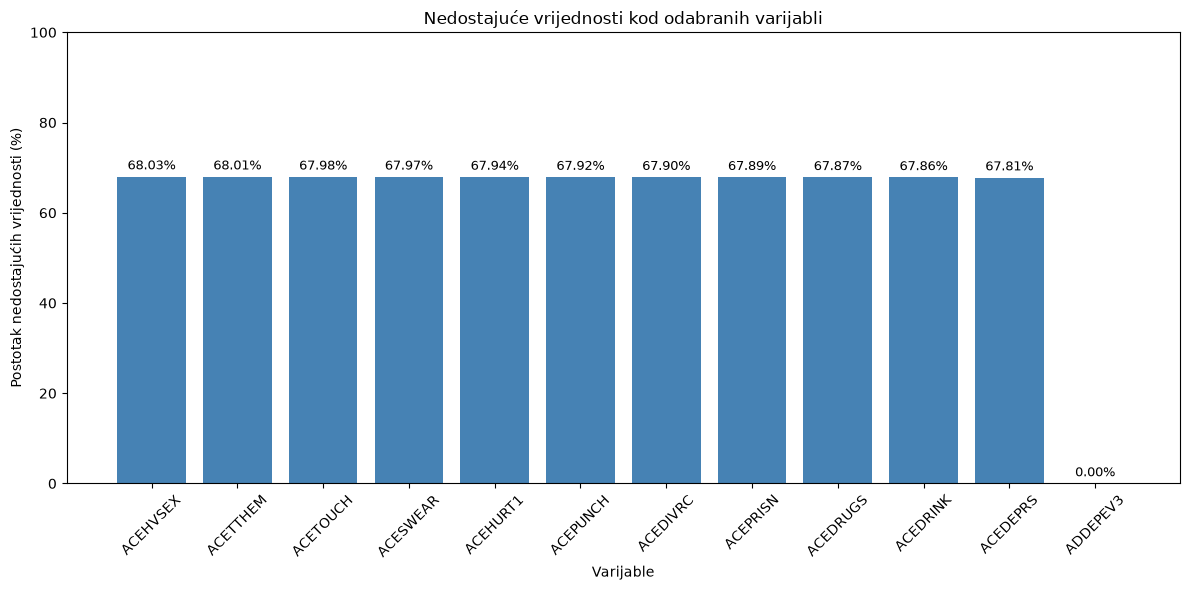

In [9]:
ace_nedostajuci = nedostajuci[
    nedostajuci["Varijabla"].str.startswith("ACE") |
    (nedostajuci["Varijabla"] == "ADDEPEV3")
]

display(ace_nedostajuci)

plt.figure(figsize=(12, 6))

stupci = plt.bar(
    ace_nedostajuci["Varijabla"],
    ace_nedostajuci["Postotak nedostajucih"],
    color="steelblue"
)

plt.bar_label(stupci, fmt="%.2f%%", padding=3, fontsize=9)

plt.title("Nedostajuće vrijednosti kod odabranih varijabli")
plt.xlabel("Varijable")
plt.ylabel("Postotak nedostajućih vrijednosti (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()

plt.savefig("grafikon_1.png", dpi=300)
plt.show()

## 2.3. Provjera potpunosti zapisa

In [10]:
ace_kolone = [c for c in df.columns if c.startswith("ACE")]

odabrane_kolone = ace_kolone + ["ADDEPEV3"]

potpunost = pd.DataFrame({
    "Obuhvat analize": [
        "Sve varijable",
        "ACE varijable i ADDEPEV3"
    ],
    "Potpuno popunjeni zapisi": [
        df.notna().all(axis=1).sum(),
        df[odabrane_kolone].notna().all(axis=1).sum()
    ],
    "Nepotpuni zapisi": [
        df.isna().any(axis=1).sum(),
        df[odabrane_kolone].isna().any(axis=1).sum()
    ]
})

display(potpunost)

print("Zapisi bez ijednog ACE odgovora:",
      df[ace_kolone].isna().all(axis=1).sum())

print("Udio potpuno popunjenih odabranih zapisa:",
      round(df[odabrane_kolone].notna().all(axis=1).mean() * 100, 2), "%")

,Obuhvat analize,Potpuno popunjeni zapisi,Nepotpuni zapisi
0,Sve varijable,0,401958
1,ACE varijable i ADDEPEV3,128496,273462


Zapisi bez ijednog ACE odgovora: 272569
Udio potpuno popunjenih odabranih zapisa: 31.97 %


## 2.4. Provjera duplikata

In [11]:
broj_duplikata = df.duplicated().sum()

print("Broj potpuno jednakih redova:", broj_duplikata)

print("Postotak duplikata:",
      round(broj_duplikata / len(df) * 100, 2), "%")

Broj potpuno jednakih redova: 0
Postotak duplikata: 0.0 %


## 2.5. Provjera nelogičnih i neusklađenih vrijednosti

### Provjera posebnih kodova odgovora

In [12]:
for kolona in odabrane_kolone:
    print("\nVarijabla:", kolona)
    display(df[kolona].value_counts(dropna=False).sort_index().to_frame("Broj odgovora"))

posebni_odgovori = pd.DataFrame({
    "Varijabla": odabrane_kolone,
    "Ne znam (7)": [(df[k] == 7).sum() for k in odabrane_kolone],
    "Roditelji nisu bili u braku (8)": [
        (df[k] == 8).sum() if k == "ACEDIVRC" else "-"
        for k in odabrane_kolone
    ],
    "Odbijam odgovoriti (9)": [(df[k] == 9).sum() for k in odabrane_kolone]
})

display(posebni_odgovori)


Varijabla: ACEDEPRS


,Broj odgovora
ACEDEPRS,
1.0,20591
2.0,106213
7.0,985
9.0,1597
NaN,272572



Varijabla: ACEDRINK


,Broj odgovora
ACEDRINK,
1.0,28269
2.0,99004
7.0,439
9.0,1493
NaN,272753



Varijabla: ACEDRUGS


,Broj odgovora
ACEDRUGS,
1.0,12165
2.0,115022
7.0,546
9.0,1406
NaN,272819


... (15 outputs left out)

,Broj odgovora
ACEHVSEX,
1.0,119727
2.0,2030
3.0,3843
7.0,361
9.0,2538
NaN,273459



Varijabla: ADDEPEV3


,Broj odgovora
ADDEPEV3,
1.0,75820
2.0,324035
7.0,1476
9.0,621
NaN,6


,Varijabla,Ne znam (7),Roditelji nisu bili u braku (8),Odbijam odgovoriti (9)
0,ACEDEPRS,985,-,1597
1,ACEDRINK,439,-,1493
2,ACEDRUGS,546,-,1406
3,ACEPRISN,280,-,1406
4,ACEDIVRC,668,1621,1547
5,ACEPUNCH,1688,-,2113
6,ACEHURT1,732,-,2273
7,ACESWEAR,1379,-,2239
8,ACETOUCH,402,-,2646
9,ACETTHEM,457,-,2519


### Provjera valjanih odgovora

In [13]:
popunjeni = df[odabrane_kolone].notna().all(axis=1)

posebni_kodovi = df[odabrane_kolone].isin([7, 9]).any(axis=1)

valjani = popunjeni & ~posebni_kodovi

print("Potpuno popunjeni zapisi:",
      popunjeni.sum())

print("Popunjeni zapisi s kodovima 7 ili 9:",
      (popunjeni & posebni_kodovi).sum())

print("Zapisi sa svim valjanim odgovorima:",
      valjani.sum())

print("Udio valjanih zapisa u izvornom datasetu:",
      round(valjani.sum() / len(df) * 100, 2), "%")

Potpuno popunjeni zapisi: 128496
Popunjeni zapisi s kodovima 7 ili 9: 11158
Zapisi sa svim valjanim odgovorima: 117338
Udio valjanih zapisa u izvornom datasetu: 29.19 %


### Provjera numeričkih vrijednosti

In [14]:
numericke_kolone = [
    "_AGE80",
    "SLEPTIM1",
    "MENTHLTH",
    "PHYSHLTH",
    "HTM4",
    "WTKG3",
    "_BMI5"
]

numericki_pregled = pd.DataFrame({
    "Varijabla": numericke_kolone,
    "Minimum": [df[k].min() for k in numericke_kolone],
    "Maksimum": [df[k].max() for k in numericke_kolone]
})

display(numericki_pregled)

,Varijabla,Minimum,Maksimum
0,_AGE80,18.0,80.0
1,SLEPTIM1,1.0,99.0
2,MENTHLTH,1.0,99.0
3,PHYSHLTH,1.0,99.0
4,HTM4,91.0,241.0
5,WTKG3,2268.0,29030.0
6,_BMI5,1202.0,9843.0


### Provjera raspona vrijednosti

In [15]:
print("Dob izvan dozvoljenog raspona:",
      (df["_AGE80"].notna() &
       ~df["_AGE80"].between(18, 80)).sum())

for kolona in ["SLEPTIM1", "MENTHLTH", "PHYSHLTH"]:
    print("\nVarijabla:", kolona)
    display(
        df[kolona].value_counts().sort_index()
        .to_frame("Broj zapisa")
    )

Dob izvan dozvoljenog raspona: 0

Varijabla: SLEPTIM1


,Broj zapisa
SLEPTIM1,
1.0,762
2.0,1102
3.0,2680
4.0,9985
5.0,24431
6.0,82622
7.0,118786
8.0,122257
9.0,19836



Varijabla: MENTHLTH


,Broj zapisa
MENTHLTH,
1.0,11144
2.0,19591
3.0,12500
4.0,6344
5.0,16705
6.0,1794
7.0,6524
8.0,1314
9.0,252



Varijabla: PHYSHLTH


,Broj zapisa
PHYSHLTH,
1.0,12492
2.0,17864
3.0,10371
4.0,5396
5.0,9192
6.0,1531
7.0,5692
8.0,1149
9.0,234


### Provjera jedinica mjere

In [16]:
display(
    df[["HEIGHT3", "HTM4", "WEIGHT2",
        "WTKG3", "_BMI5"]].head(10)
)

,HEIGHT3,HTM4,WEIGHT2,WTKG3,_BMI5
0,507.0,170.0,106.0,4808.0,1660.0
1,504.0,163.0,170.0,7711.0,2918.0
2,508.0,173.0,7777.0,NaN,NaN
3,9999.0,NaN,9999.0,NaN,NaN
4,506.0,168.0,126.0,5715.0,2034.0
5,509.0,175.0,180.0,8165.0,2658.0
6,506.0,168.0,150.0,6804.0,2421.0
7,503.0,160.0,150.0,6804.0,2657.0
8,511.0,180.0,170.0,7711.0,2371.0
9,503.0,160.0,163.0,7394.0,2887.0


### Provjera datumskih vrijednosti

In [17]:
datumi = pd.to_datetime(
    df["IDATE"].str.decode("utf-8"),
    format="%m%d%Y",
    errors="coerce"
)

print("Neispravni datumi:",
      (df["IDATE"].notna() & datumi.isna()).sum())

print("Najraniji datum:", datumi.min())
print("Najkasniji datum:", datumi.max())

mjeseci = pd.to_numeric(df["IMONTH"], errors="coerce")
dani = pd.to_numeric(df["IDAY"], errors="coerce")
godine = pd.to_numeric(df["IYEAR"], errors="coerce")

neuskladjeni_datumi = datumi.notna() & (
    (datumi.dt.month != mjeseci) |
    (datumi.dt.day != dani) |
    (datumi.dt.year != godine)
)

print("Neuskladjeni datumski zapisi:",
      neuskladjeni_datumi.sum())

Neispravni datumi: 0
Najraniji datum: 2020-01-02 00:00:00
Najkasniji datum: 2021-03-18 00:00:00
Neuskladjeni datumski zapisi: 0


### Provjera usklađenosti BMI vrijednosti

In [18]:
visina = df["HTM4"] / 100
tezina = df["WTKG3"] / 100

izracunati_bmi = tezina / (visina ** 2)
evidentirani_bmi = df["_BMI5"] / 100

razlika = (izracunati_bmi - evidentirani_bmi).abs()

print("Broj uporedivih BMI zapisa:",
      razlika.notna().sum())

print("Najveca razlika:", razlika.max())

print("Broj odstupanja vecih od 1:",
      (razlika > 1).sum())

Broj uporedivih BMI zapisa: 360601
Najveca razlika: 0.865558507426627
Broj odstupanja vecih od 1: 0


## 2.6. Analiza obrazaca nedostajanja podataka

### Nedostajanje ACE podataka prema državi, spolu i dobnoj grupi

In [19]:
bez_ace = df[ace_kolone].isna().all(axis=1)

obrasci = pd.DataFrame({
    "Drzava": df["_STATE"],
    "Spol": df["SEXVAR"],
    "Dobna grupa": df["_AGEG5YR"],
    "Bez ACE podataka": bez_ace
})

for grupa in ["Drzava", "Spol", "Dobna grupa"]:
    rezultat = obrasci.groupby(grupa)["Bez ACE podataka"].agg(
        ["count", "sum", "mean"]
    )

    rezultat.columns = [
        "Ukupno ispitanika",
        "Bez ACE podataka",
        "Postotak nedostajucih"
    ]

    rezultat["Postotak nedostajucih"] = (
        rezultat["Postotak nedostajucih"] * 100
    ).round(2)

    print("\nNedostajuci ACE podaci prema:", grupa)
    display(rezultat)

    rezultat.to_csv(
        "nedostajuci_ACE_" + grupa.replace(" ", "_") + ".csv"
    )


Nedostajuci ACE podaci prema: Drzava


,Ukupno ispitanika,Bez ACE podataka,Postotak nedostajucih
Drzava,,,
1.0,5341,775,14.51
2.0,3675,3675,100.00
4.0,10291,2009,19.52
5.0,5244,5244,100.00
6.0,4798,4798,100.00
8.0,10184,10184,100.00
9.0,8982,8982,100.00
10.0,4025,4025,100.00
11.0,3428,654,19.08



Nedostajuci ACE podaci prema: Spol


,Ukupno ispitanika,Bez ACE podataka,Postotak nedostajucih
Spol,,,
1.0,183942,125489,68.22
2.0,218016,147080,67.46



Nedostajuci ACE podaci prema: Dobna grupa


,Ukupno ispitanika,Bez ACE podataka,Postotak nedostajucih
Dobna grupa,,,
1.0,25648,17788,69.35
2.0,20911,14854,71.03
3.0,23408,16293,69.60
4.0,25492,17380,68.18
5.0,25729,17471,67.90
6.0,26428,18117,68.55
7.0,31110,21579,69.36
8.0,36219,24920,68.80
9.0,41151,27982,68.00


### Grafički prikaz nedostajanja ACE podataka prema području anketiranja

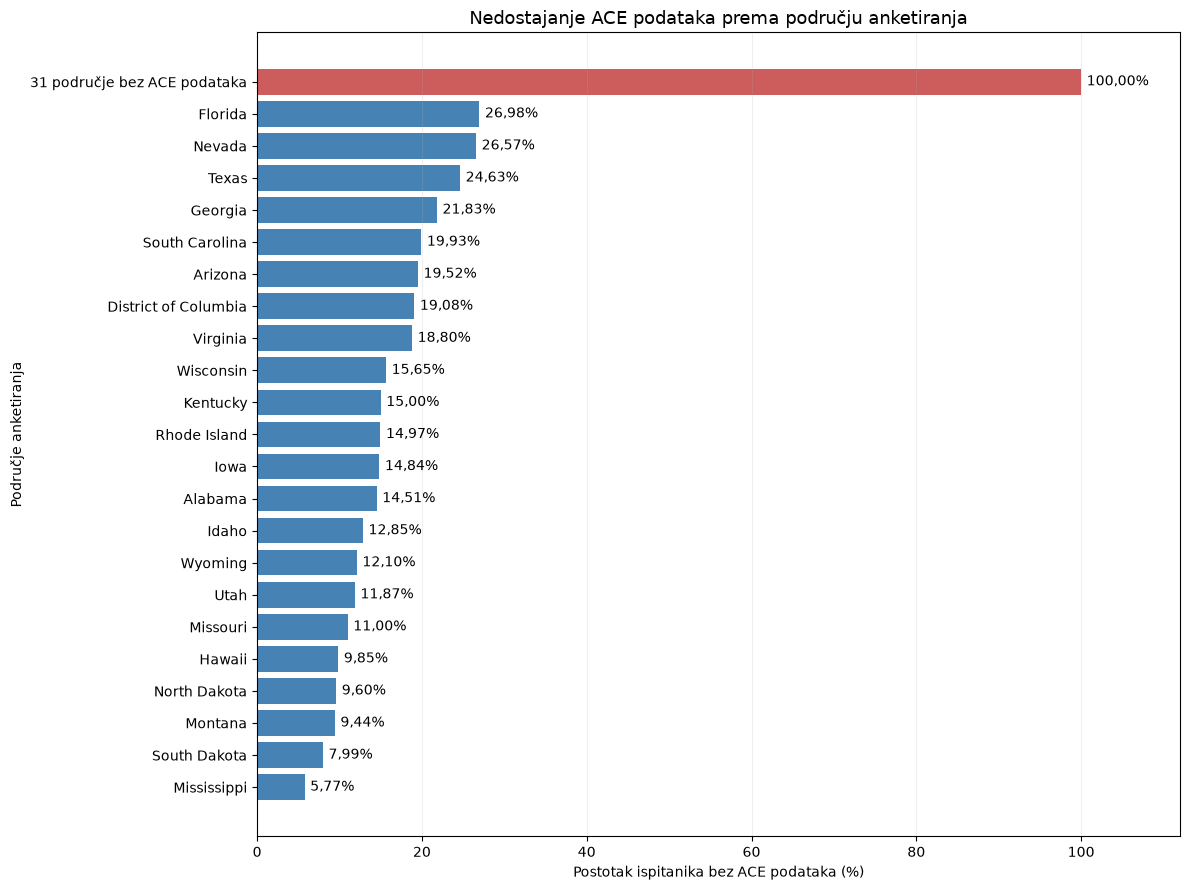

In [20]:
nazivi_drzava = {
    1: "Alabama",
    4: "Arizona",
    11: "District of Columbia",
    12: "Florida",
    13: "Georgia",
    15: "Hawaii",
    16: "Idaho",
    19: "Iowa",
    21: "Kentucky",
    28: "Mississippi",
    29: "Missouri",
    30: "Montana",
    32: "Nevada",
    38: "North Dakota",
    44: "Rhode Island",
    45: "South Carolina",
    46: "South Dakota",
    48: "Texas",
    49: "Utah",
    51: "Virginia",
    55: "Wisconsin",
    56: "Wyoming"
}

nedostajanje_drzave = (
    obrasci.groupby("Drzava")["Bez ACE podataka"]
    .mean() * 100
)

potpuno_nedostaju = (nedostajanje_drzave == 100).sum()

prikaz = nedostajanje_drzave[
    nedostajanje_drzave < 100
].copy()

prikaz.index = prikaz.index.map(
    lambda x: nazivi_drzava.get(int(x), str(int(x)))
)

prikaz[f"{potpuno_nedostaju} područje bez ACE podataka"] = 100

prikaz = prikaz.sort_values()

boje = [
    "indianred" if x == 100 else "steelblue"
    for x in prikaz.values
]

plt.figure(figsize=(12, 9))

stupci = plt.barh(
    prikaz.index,
    prikaz.values,
    color=boje
)

plt.bar_label(
    stupci,
    labels=[
        f"{x:.2f}%".replace(".", ",")
        for x in prikaz.values
    ],
    padding=4,
    fontsize=10
)

plt.title(
    "Nedostajanje ACE podataka prema području anketiranja",
    fontsize=13
)

plt.xlabel("Postotak ispitanika bez ACE podataka (%)")
plt.ylabel("Područje anketiranja")
plt.xlim(0, 112)
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()

plt.savefig("grafikon_2.png", dpi=300)
plt.show()

# 3. Razvrstavanje varijabli prema mjernoj ljestvici

Razvrstavanje varijabli izvršeno je na osnovu njihovog značenja i službene Codebook dokumentacije. Numerički zapis varijable ne znači nužno da je ona kvantitativna.

In [21]:
klasifikacija = pd.read_csv("klasifikacija_279_varijabli.csv")

display(klasifikacija.head(10))

print("Broj klasifikovanih varijabli:", len(klasifikacija))

print("Neklasifikovane varijable:",
      set(df.columns) - set(klasifikacija["Varijabla"]))

print("Varijable koje nisu u datasetu:",
      set(klasifikacija["Varijabla"]) - set(df.columns))

print("Ponovljene varijable:",
      klasifikacija["Varijabla"].duplicated().sum())

print("Nazivi kolona:", klasifikacija.columns.tolist())

,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,_STATE,State FIPS Code,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
1,FMONTH,File Month,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
2,IDATE,Interview Date,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
3,IMONTH,Interview Month,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
4,IDAY,Interview Day,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
5,IYEAR,Interview Year,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
6,DISPCODE,Final Disposition,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
7,SEQNO,Annual Sequence Number,Identifikacijske i tehničke oznake,Oznaka zapisa ili uzorkovanja; ne predstavlja ...,NaN,Tehnička namjena; ne koristiti nekritički u an...
8,_PSU,Primary Sampling Unit,Identifikacijske i tehničke oznake,Oznaka zapisa ili uzorkovanja; ne predstavlja ...,NaN,Tehnička namjena; ne koristiti nekritički u an...
9,CTELENM1,Correct telephone number?,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN


Broj klasifikovanih varijabli: 279
Neklasifikovane varijable: set()
Varijable koje nisu u datasetu: set()
Ponovljene varijable: 0
Nazivi kolona: ['Varijabla', 'Opis (Codebook)', 'Mjerna ljestvica', 'Obrazlozenje', 'Prirodni redoslijed', 'Napomena']


### Pregled broja varijabli prema mjernoj ljestvici

In [22]:
display(
    klasifikacija["Mjerna ljestvica"]
    .value_counts()
    .to_frame("Broj varijabli")
)

print("Broj praznih mjernih ljestvica:",
      klasifikacija["Mjerna ljestvica"].isna().sum())

,Broj varijabli
Mjerna ljestvica,
Nominalne,180
Ordinalne,45
Kvantitativne – diskretne,29
Kvantitativne – kontinuirane,15
Datumske i datumske komponente,7
Identifikacijske i tehničke oznake,3


Broj praznih mjernih ljestvica: 0


## 3.1. Nominalne varijable



In [23]:
nominalne = klasifikacija[
    klasifikacija["Mjerna ljestvica"] == "Nominalne"
]

display(nominalne.reset_index(drop=True))

print("Broj nominalnih varijabli:", len(nominalne))

,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,_STATE,State FIPS Code,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
1,DISPCODE,Final Disposition,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
2,CTELENM1,Correct telephone number?,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
3,PVTRESD1,Private Residence?,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
4,COLGHOUS,Do you live in college housing?,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
...,...,...,...,...,...,...
175,_STOLDNA,Respondents aged 50-75 who have had a stool DN...,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
176,_VIRCOLN,Respondents aged 50-75 who have had a virtual ...,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
177,_SBONTIM,Respondents aged 50-75 who have had a sigmoido...,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
178,_CRCREC1,Respondents aged 50-75 who have fully met the ...,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN


Broj nominalnih varijabli: 180


## 3.2. Ordinalne varijable



In [24]:
ordinalne = klasifikacija[
    klasifikacija["Mjerna ljestvica"] == "Ordinalne"
]

display(ordinalne.reset_index(drop=True))

print("Broj ordinalnih varijabli:", len(ordinalne))

,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,GENHLTH,General Health,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",1 → 2 → 3 → 4 → 5 (odličan → loš),NaN
1,PERSDOC2,Multiple Health Care Professionals,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",3 → 1 → 2 (nijedan → jedan → više),NaN
2,CHECKUP1,Length of time since last routine checkup,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",Od kraćeg do dužeg vremena; nikada odvojeno ak...,NaN
3,LASTDEN4,Last Visited Dentist or Dental Clinic,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",Od kraćeg do dužeg vremena; nikada odvojeno ak...,NaN
4,RMVTETH4,Number of Permanent Teeth Removed,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",8 → 1 → 2 → 3 (nijedan → svi),NaN
5,EDUCA,Education Level,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",Od najnižeg do najvišeg nivoa,NaN
6,INCOME2,Income Level,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",Od najnižeg do najvišeg nivoa,NaN
7,SMOKDAY2,Frequency of Days Now Smoking,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",3 → 2 → 1 (nikada/sada ne → neki dani → svaki ...,NaN
8,LASTSMK2,Interval Since Last Smoked,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",Od kraćeg do dužeg vremena; nikada odvojeno ak...,NaN
9,USENOW3,Use of Smokeless Tobacco Products,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",3 → 2 → 1 (nikada/sada ne → neki dani → svaki ...,NaN


Broj ordinalnih varijabli: 45


## 3.3. Kvantitativne varijable



In [25]:
diskretne = klasifikacija[
    klasifikacija["Mjerna ljestvica"] == "Kvantitativne – diskretne"
]

kontinuirane = klasifikacija[
    klasifikacija["Mjerna ljestvica"] == "Kvantitativne – kontinuirane"
]

print("Diskretne varijable:")
display(diskretne.reset_index(drop=True))

print("Kontinuirane varijable:")
display(kontinuirane.reset_index(drop=True))

print("Broj diskretnih varijabli:", len(diskretne))
print("Broj kontinuiranih varijabli:", len(kontinuirane))
print("Ukupan broj kvantitativnih varijabli:",
      len(diskretne) + len(kontinuirane))

Diskretne varijable:


,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,NUMADULT,Number of Adults in Household,Kvantitativne – diskretne,Broj odraslih; gornja grupa objedinjena u izvj...,NaN,NaN
1,NUMMEN,Number of Adult men in Household,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
2,NUMWOMEN,Number of Adult women in Household,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
3,HHADULT,Number of Adults in Household,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
4,PHYSHLTH,Number of Days Physical Health Not Good,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
5,MENTHLTH,Number of Days Mental Health Not Good,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
6,POORHLTH,Poor Physical or Mental Health,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
7,SLEPTIM1,How Much Time Do You Sleep,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
8,DIABAGE3,Age When Told Had Diabetes,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
9,NUMPHON3,Residential Phones,Kvantitativne – diskretne,Broj telefona; 6 znači šest ili više.,NaN,NaN


Kontinuirane varijable:


,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,WEIGHT2,Reported Weight in Pounds,Kvantitativne – kontinuirane,Masa uz kodiranu jedinicu (lb/kg).,NaN,NaN
1,HEIGHT3,Reported Height in Feet and Inches,Kvantitativne – kontinuirane,Visina uz kodiranu jedinicu (stope/inči ili me...,NaN,NaN
2,_STRWT,Stratum weight,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
3,_RAWRAKE,Raw weighting factor used in raking,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
4,_WT2RAKE,Design weight use in raking,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
5,_CLLCPWT,Final child weight: Land-line and Cell-Phone data,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
6,_DUALCOR,Dual Phone Use Correction Factor,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
7,_LLCPWT2,Truncated design weight used in adult combined...,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
8,_LLCPWT,Final weight: Land-line and cell-phone data,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
9,HTIN4,Computed Height in Inches,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,NaN


Broj diskretnih varijabli: 29
Broj kontinuiranih varijabli: 15
Ukupan broj kvantitativnih varijabli: 44


## 3.4. Varijable posebne namjene



In [26]:
datumske = klasifikacija[
    klasifikacija["Mjerna ljestvica"] == "Datumske i datumske komponente"
]

identifikacijske = klasifikacija[
    klasifikacija["Mjerna ljestvica"] == "Identifikacijske i tehničke oznake"
]

print("Datumske varijable:")
display(datumske.reset_index(drop=True))

print("Identifikacijske i tehničke oznake:")
display(identifikacijske.reset_index(drop=True))

print("Broj datumskih varijabli:", len(datumske))
print("Broj identifikacijskih i tehnickih oznaka:", len(identifikacijske))

Datumske varijable:


,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,FMONTH,File Month,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
1,IDATE,Interview Date,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
2,IMONTH,Interview Month,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
3,IDAY,Interview Day,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
4,IYEAR,Interview Year,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
5,FLSHTMY3,When did you receive your most recent seasonal...,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
6,HIVTSTD3,Month and Year of Last HIV Test,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN


Identifikacijske i tehničke oznake:


,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,SEQNO,Annual Sequence Number,Identifikacijske i tehničke oznake,Oznaka zapisa ili uzorkovanja; ne predstavlja ...,NaN,Tehnička namjena; ne koristiti nekritički u an...
1,_PSU,Primary Sampling Unit,Identifikacijske i tehničke oznake,Oznaka zapisa ili uzorkovanja; ne predstavlja ...,NaN,Tehnička namjena; ne koristiti nekritički u an...
2,_STSTR,Sample Design Stratification Variable,Identifikacijske i tehničke oznake,Oznaka zapisa ili uzorkovanja; ne predstavlja ...,NaN,Tehnička namjena; ne koristiti nekritički u an...


Broj datumskih varijabli: 7
Broj identifikacijskih i tehnickih oznaka: 3


## 3.5. Sažeti pregled nivoa mjerenja varijabli



In [27]:
sazetak_mjerenja = pd.DataFrame({
    "Vrsta varijable": [
        "Nominalne",
        "Ordinalne",
        "Kvantitativne – diskretne",
        "Kvantitativne – kontinuirane",
        "Datumske i datumske komponente",
        "Identifikacijske i tehničke oznake",
        "Ukupno"
    ],
    "Broj varijabli": [
        len(nominalne),
        len(ordinalne),
        len(diskretne),
        len(kontinuirane),
        len(datumske),
        len(identifikacijske),
        len(klasifikacija)
    ]
})

display(sazetak_mjerenja)

,Vrsta varijable,Broj varijabli
0,Nominalne,180
1,Ordinalne,45
2,Kvantitativne – diskretne,29
3,Kvantitativne – kontinuirane,15
4,Datumske i datumske komponente,7
5,Identifikacijske i tehničke oznake,3
6,Ukupno,279



## 4. Deskriptivna analiza kvalitativnih varijabli

### 4.1. Frekvencijska analiza nominalnih i ordinalnih varijabli

Za nominalne i ordinalne varijable izračunavam apsolutne i relativne frekvencije te broj kategorija. Posebni kodovi odgovora i nedostajuće vrijednosti prikazuju se odvojeno.


In [28]:

import pandas as pd

varijable = {
    "SEXVAR": {
        1: "Muški",
        2: "Ženski"
    },
    "ADDEPEV3": {
        1: "Da",
        2: "Ne",
        7: "Ne znam",
        9: "Odbijam odgovoriti"
    },
    "ACEDEPRS": {
        1: "Da",
        2: "Ne",
        7: "Ne znam",
        9: "Odbijam odgovoriti"
    },
    "ACEPUNCH": {
        1: "Nikada",
        2: "Jednom",
        3: "Više od jednom",
        7: "Ne znam",
        9: "Odbijam odgovoriti"
    }
}

for naziv, kategorije in varijable.items():
    frekvencije = df[naziv].value_counts(dropna=False).sort_index()

    tabela = pd.DataFrame({
        "Kategorija": [
            "Nedostaje" if pd.isna(kod) else kategorije.get(kod, str(kod))
            for kod in frekvencije.index
        ],
        "Frekvencija (n)": frekvencije.values,
        "Postotak (%)": (frekvencije.values / len(df) * 100).round(2)
    })

    print(f"\nVarijabla: {naziv}")
    print(f"Broj kategorija (bez NaN): {df[naziv].nunique()}")
    display(tabela)

    tabela.to_csv(
        f"frekvencije_{naziv}.csv",
        index=False,
        encoding="utf-8-sig"
    )



Varijabla: SEXVAR


Broj kategorija (bez NaN): 2


,Kategorija,Frekvencija (n),Postotak (%)
0,Muški,183942,45.76
1,Ženski,218016,54.24



Varijabla: ADDEPEV3
Broj kategorija (bez NaN): 4


,Kategorija,Frekvencija (n),Postotak (%)
0,Da,75820,18.86
1,Ne,324035,80.61
2,Ne znam,1476,0.37
3,Odbijam odgovoriti,621,0.15
4,Nedostaje,6,0.00



Varijabla: ACEDEPRS
Broj kategorija (bez NaN): 4


,Kategorija,Frekvencija (n),Postotak (%)
0,Da,20591,5.12
1,Ne,106213,26.42
2,Ne znam,985,0.25
3,Odbijam odgovoriti,1597,0.40
4,Nedostaje,272572,67.81



Varijabla: ACEPUNCH
Broj kategorija (bez NaN): 5


,Kategorija,Frekvencija (n),Postotak (%)
0,Nikada,106023,26.38
1,Jednom,4845,1.21
2,Više od jednom,14299,3.56
3,Ne znam,1688,0.42
4,Odbijam odgovoriti,2113,0.53
5,Nedostaje,272990,67.92



#### Grafički prikaz zastupljenosti kategorija

Stupčastim grafikonima prikazujem raspodjelu odgovora kod odabranih nominalnih i ordinalnih varijabli. Kod ordinalnih varijabli zadržavam prirodni redoslijed kategorija.


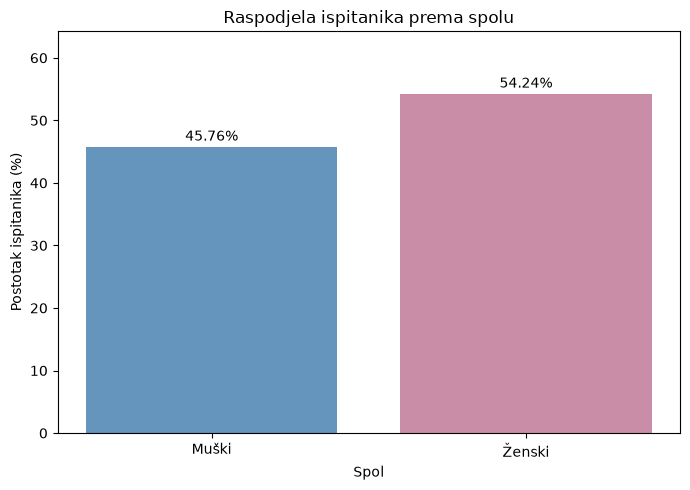

In [29]:

import matplotlib.pyplot as plt

spol = df["SEXVAR"].map({
    1: "Muški",
    2: "Ženski"
})

broj = spol.value_counts().reindex(["Muški", "Ženski"])
postotak = broj / broj.sum() * 100

fig, ax = plt.subplots(figsize=(7, 5))

stupci = ax.bar(broj.index, postotak, color=["#6594bd", "#c98da8"])

for stupac, vrijednost in zip(stupci, postotak):
    ax.text(
        stupac.get_x() + stupac.get_width() / 2,
        vrijednost + 1,
        f"{vrijednost:.2f}%",
        ha="center"
    )

ax.set_title("Raspodjela ispitanika prema spolu")
ax.set_xlabel("Spol")
ax.set_ylabel("Postotak ispitanika (%)")
ax.set_ylim(0, max(postotak) + 10)

plt.tight_layout()
plt.savefig("grafikon_spol.png", dpi=300, bbox_inches="tight")
plt.show()


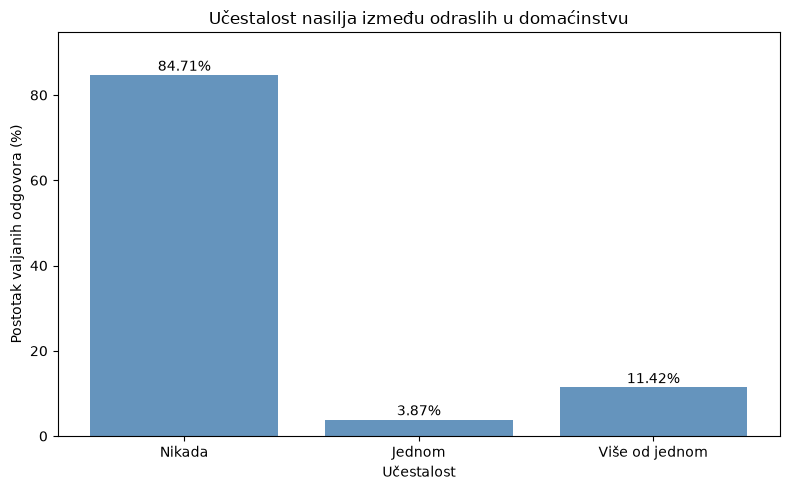

In [30]:

kategorije = {
    1: "Nikada",
    2: "Jednom",
    3: "Više od jednom"
}

podaci = df["ACEPUNCH"]
valjani = podaci[podaci.isin(kategorije.keys())]

broj = valjani.value_counts().reindex([1, 2, 3], fill_value=0)
postotak = broj / broj.sum() * 100

fig, ax = plt.subplots(figsize=(8, 5))

stupci = ax.bar(
    [kategorije[i] for i in broj.index],
    postotak,
    color="#6594bd"
)

for stupac, vrijednost in zip(stupci, postotak):
    ax.text(
        stupac.get_x() + stupac.get_width() / 2,
        vrijednost + 1,
        f"{vrijednost:.2f}%",
        ha="center"
    )

ax.set_title("Učestalost nasilja između odraslih u domaćinstvu")
ax.set_xlabel("Učestalost")
ax.set_ylabel("Postotak valjanih odgovora (%)")
ax.set_ylim(0, max(postotak) + 10)

plt.tight_layout()
plt.savefig("grafikon_acepunch.png", dpi=300, bbox_inches="tight")
plt.show()



#### Frekvencijski pregled svih kategorijskih varijabli

Frekvencijsku analizu proširujem na sve nominalne i ordinalne varijable. Za svaku varijablu računam broj kategorija, apsolutne frekvencije i postotke. Rezultate čuvam u CSV datoteci radi preglednijeg prikaza.


In [31]:

import pandas as pd

klasifikacija = pd.read_csv(
    "klasifikacija_279_varijabli.csv",
    encoding="utf-8-sig"
)

print("Nazivi kolona:")
print(klasifikacija.columns.tolist())

print("\nPrvih pet zapisa:")
display(klasifikacija.head())


Nazivi kolona:
['Varijabla', 'Opis (Codebook)', 'Mjerna ljestvica', 'Obrazlozenje', 'Prirodni redoslijed', 'Napomena']

Prvih pet zapisa:


,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,_STATE,State FIPS Code,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
1,FMONTH,File Month,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
2,IDATE,Interview Date,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
3,IMONTH,Interview Month,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
4,IDAY,Interview Day,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN


In [32]:

from analiza import frekvencije_vise_varijabli

kategorijske = klasifikacija[
    klasifikacija["Mjerna ljestvica"].str.lower().str.contains(
        "nominalne|ordinalne", na=False
    )
]["Varijabla"].tolist()

kategorijske = [v for v in kategorijske if v in df.columns]

print("Broj kategorijskih varijabli:", len(kategorijske))

sve_frekvencije = frekvencije_vise_varijabli(
    df, kategorijske
)

sve_frekvencije.to_csv(
    "frekvencije_svih_kategorijskih_varijabli.csv",
    index=False,
    encoding="utf-8-sig"
)

display(sve_frekvencije.head(20))


Broj redova: 401958
Broj kolona: 279
   _STATE  FMONTH        IDATE IMONTH   IDAY    IYEAR  DISPCODE  \
0     1.0     1.0  b'01042020'  b'01'  b'04'  b'2020'    1100.0   
1     1.0     1.0  b'02072020'  b'02'  b'07'  b'2020'    1200.0   
2     1.0     1.0  b'01232020'  b'01'  b'23'  b'2020'    1100.0   
3     1.0     1.0  b'01092020'  b'01'  b'09'  b'2020'    1100.0   
4     1.0     1.0  b'01042020'  b'01'  b'04'  b'2020'    1100.0   

           SEQNO          _PSU  CTELENM1  ...  _RFPSA23  _CLNSCPY  _SGMSCPY  \
0  b'2020000001'  2.020000e+09       1.0  ...       NaN       1.0       3.0   
1  b'2020000002'  2.020000e+09       1.0  ...       NaN       NaN       NaN   
2  b'2020000003'  2.020000e+09       1.0  ...       NaN       1.0       3.0   
3  b'2020000004'  2.020000e+09       1.0  ...       NaN       NaN       NaN   
4  b'2020000005'  2.020000e+09       1.0  ...       NaN       NaN       NaN   

   _SGMS10Y  _RFBLDS4  _STOLDNA  _VIRCOLN  _SBONTIM  _CRCREC1  _AIDTST4  
0       3.0

,Varijabla,Kategorija,Frekvencija (n),Postotak (%)
0,_STATE,1.0,5341,1.33
1,_STATE,2.0,3675,0.91
2,_STATE,4.0,10291,2.56
3,_STATE,5.0,5244,1.30
4,_STATE,6.0,4798,1.19
5,_STATE,8.0,10184,2.53
6,_STATE,9.0,8982,2.23
7,_STATE,10.0,4025,1.00
8,_STATE,11.0,3428,0.85
9,_STATE,12.0,11799,2.94


In [33]:

print("Broj varijabli prema mjernoj ljestvici:")

display(
    klasifikacija["Mjerna ljestvica"]
    .value_counts(dropna=False)
    .to_frame("Broj varijabli")
)

print("\nUkupan broj kategorijskih varijabli:", len(kategorijske))

print("\nBroj kategorija po varijabli:")

pregled_kategorija = pd.DataFrame({
    "Varijabla": kategorijske,
    "Broj kategorija": [
        df[v].nunique(dropna=True) for v in kategorijske
    ]
})

display(pregled_kategorija.head(20))


Broj varijabli prema mjernoj ljestvici:


,Broj varijabli
Mjerna ljestvica,
Nominalne,180
Ordinalne,45
Kvantitativne – diskretne,29
Kvantitativne – kontinuirane,15
Datumske i datumske komponente,7
Identifikacijske i tehničke oznake,3



Ukupan broj kategorijskih varijabli: 225

Broj kategorija po varijabli:


,Varijabla,Broj kategorija
0,_STATE,53
1,DISPCODE,2
2,CTELENM1,1
3,PVTRESD1,2
4,COLGHOUS,1
5,STATERE1,1
6,CELPHONE,1
7,LADULT1,2
8,COLGSEX,2
9,LANDSEX,4



#### Pregled rijetkih kategorija

Provjeravam koje su kategorije zastupljene kod manje od 1% popunjenih odgovora pojedine varijable. Ovaj pregled omogućava prepoznavanje rijetkih i potencijalno problematičnih kategorija.


In [36]:

from analiza import pregled_rijetkih_kategorija

rijetke_kategorije = pregled_rijetkih_kategorija(
    sve_frekvencije,
    prag=1
)

print("Broj rijetkih kategorija:", len(rijetke_kategorije))

print(
    "Broj varijabli s rijetkim kategorijama:",
    rijetke_kategorije["Varijabla"].nunique()
)

display(rijetke_kategorije.head(20))

rijetke_kategorije.to_csv(
    "rijetke_kategorije.csv",
    index=False,
    encoding="utf-8-sig"
)


Broj rijetkih kategorija: 293
Broj varijabli s rijetkim kategorijama: 151


,Varijabla,Kategorija,Frekvencija (n),Postotak (%),Postotak popunjenih (%)
408,DRNKDRI2,76.0,1,0.0,0.0
390,DRNKDRI2,17.0,2,0.0,0.0
391,DRNKDRI2,18.0,2,0.0,0.0
393,DRNKDRI2,21.0,3,0.0,0.0
395,DRNKDRI2,25.0,7,0.0,0.0
394,DRNKDRI2,22.0,2,0.0,0.0
396,DRNKDRI2,26.0,1,0.0,0.0
397,DRNKDRI2,28.0,4,0.0,0.0
403,DRNKDRI2,50.0,1,0.0,0.0
398,DRNKDRI2,29.0,1,0.0,0.0


In [37]:

import importlib
import analiza

importlib.reload(analiza)


Broj redova: 401958
Broj kolona: 279
   _STATE  FMONTH        IDATE IMONTH   IDAY    IYEAR  DISPCODE  \
0     1.0     1.0  b'01042020'  b'01'  b'04'  b'2020'    1100.0   
1     1.0     1.0  b'02072020'  b'02'  b'07'  b'2020'    1200.0   
2     1.0     1.0  b'01232020'  b'01'  b'23'  b'2020'    1100.0   
3     1.0     1.0  b'01092020'  b'01'  b'09'  b'2020'    1100.0   
4     1.0     1.0  b'01042020'  b'01'  b'04'  b'2020'    1100.0   

           SEQNO          _PSU  CTELENM1  ...  _RFPSA23  _CLNSCPY  _SGMSCPY  \
0  b'2020000001'  2.020000e+09       1.0  ...       NaN       1.0       3.0   
1  b'2020000002'  2.020000e+09       1.0  ...       NaN       NaN       NaN   
2  b'2020000003'  2.020000e+09       1.0  ...       NaN       1.0       3.0   
3  b'2020000004'  2.020000e+09       1.0  ...       NaN       NaN       NaN   
4  b'2020000005'  2.020000e+09       1.0  ...       NaN       NaN       NaN   

   _SGMS10Y  _RFBLDS4  _STOLDNA  _VIRCOLN  _SBONTIM  _CRCREC1  _AIDTST4  
0       3.0

<module 'analiza' from 'c:\\Users\\Asus\\Desktop\\masinsko ucenje\\analiza.py'>


#### Rijetke kategorije kod varijabli značajnih za projekat

Posebno provjeravam rijetke vrijednosti kod ACE varijabli i varijable ADDEPEV3. Dobijene rezultate potrebno je uporediti s Codebookom kako bi se razlikovali stvarni odgovori od posebnih kodova.


In [38]:

odabrane_varijable = [
    "ACEDEPRS", "ACEDRINK", "ACEDRUGS",
    "ACEPRISN", "ACEDIVRC", "ACEPUNCH",
    "ACEHURT1", "ACESWEAR", "ACETOUCH",
    "ACETTHEM", "ACEHVSEX", "ADDEPEV3"
]

rijetke_odabrane = rijetke_kategorije[
    rijetke_kategorije["Varijabla"].isin(odabrane_varijable)
].copy()

rijetke_odabrane = rijetke_odabrane.sort_values(
    ["Varijabla", "Kategorija"]
)

print("Broj rijetkih kategorija:", len(rijetke_odabrane))

print(
    "Broj varijabli s rijetkim kategorijama:",
    rijetke_odabrane["Varijabla"].nunique()
)

display(rijetke_odabrane)

rijetke_odabrane.to_csv(
    "rijetke_kategorije_ACE_depresija.csv",
    index=False,
    encoding="utf-8-sig"
)


Broj rijetkih kategorija: 11
Broj varijabli s rijetkim kategorijama: 10


,Varijabla,Kategorija,Frekvencija (n),Postotak (%),Postotak popunjenih (%)
967,ACEDEPRS,7.0,985,0.25,0.76
987,ACEDIVRC,7.0,668,0.17,0.52
972,ACEDRINK,7.0,439,0.11,0.34
977,ACEDRUGS,7.0,546,0.14,0.42
1000,ACEHURT1,7.0,732,0.18,0.57
1024,ACEHVSEX,7.0,361,0.09,0.28
982,ACEPRISN,7.0,280,0.07,0.22
1012,ACETOUCH,7.0,402,0.10,0.31
1018,ACETTHEM,7.0,457,0.11,0.36
190,ADDEPEV3,7.0,1476,0.37,0.37



Pregledom odabranih ACE varijabli i varijable ADDEPEV3 izdvojeno je 11 rijetkih vrijednosti u 10 varijabli. Sve se odnose na posebne kodove 7 („Ne znam“) i 9 („Odbijam odgovoriti“). Ove vrijednosti ne predstavljaju konkretne odgovore o iskustvima ispitanika i potrebno ih je posebno tumačiti.



### 4.2. Analiza povezanosti kategorijskih varijabli

Pomoću tabela kontingencije analiziram odnos između odabranih kategorijskih varijabli. Prvo poredim iskustvo života s osobom koja je imala mentalne poteškoće i prijavljenu dijagnozu depresije. Prikazujem apsolutne frekvencije i postotke po redovima.


In [39]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

kategorije_ace = {
    1: "Da",
    2: "Ne"
}

kategorije_depresija = {
    1: "Da",
    2: "Ne"
}

frekvencije, postoci, broj_zapisa = analiza.tabela_kontingencije(
    df,
    "ACEDEPRS",
    "ADDEPEV3",
    kategorije_ace,
    kategorije_depresija
)

print("Broj zapisa uključenih u poređenje:", broj_zapisa)

print("\nApsolutne frekvencije:")
display(frekvencije)

print("\nPostoci po redovima (%):")
display(postoci)

frekvencije.to_csv(
    "kontingencija_ACEDEPRS_ADDEPEV3_frekvencije.csv",
    encoding="utf-8-sig"
)

postoci.to_csv(
    "kontingencija_ACEDEPRS_ADDEPEV3_postoci.csv",
    encoding="utf-8-sig"
)


Broj zapisa uključenih u poređenje: 126244

Apsolutne frekvencije:


ADDEPEV3,Da,Ne
ACEDEPRS,,
Da,9078,11365
Ne,14835,90966



Postoci po redovima (%):


ADDEPEV3,Da,Ne
ACEDEPRS,,
Da,44.41,55.59
Ne,14.02,85.98



U poređenje je uključeno 126.244 ispitanika. Prijavljena dijagnoza depresije zastupljena je kod 44,41% ispitanika koji su tokom djetinjstva živjeli s osobom koja je imala mentalne poteškoće, u odnosu na 14,02% ispitanika koji nisu prijavili takvo iskustvo.

Razlika iznosi 30,39 postotnih poena i ukazuje na izraženu povezanost između posmatranih varijabli, bez dokazivanja uzročno-posljedičnog odnosa.



#### Grafički prikaz odnosa kategorijskih varijabli

Stupčastim grafikonom prikazujem postotak ispitanika s prijavljenom dijagnozom depresije prema iskustvu života s osobom koja je imala mentalne poteškoće tokom djetinjstva.


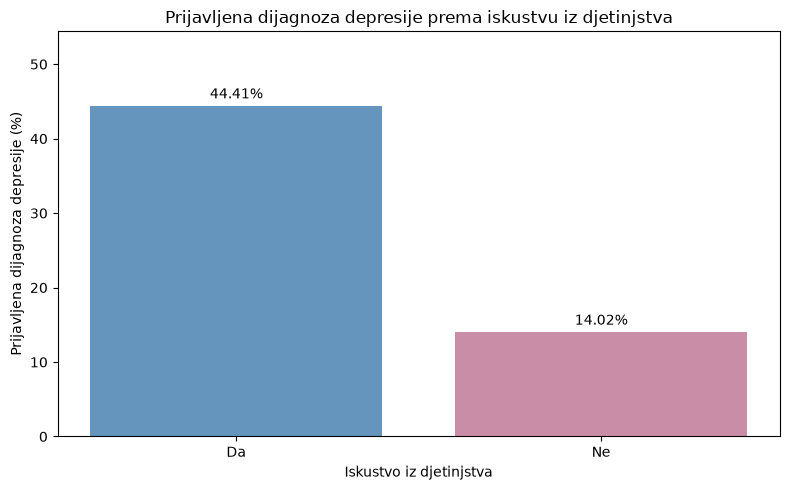

In [40]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

analiza.grafikon_kontingencije(
    postoci,
    "Da",
    "Prijavljena dijagnoza depresije prema iskustvu iz djetinjstva",
    "grafikon_depresija_ACEDEPRS.png"
)



Prijavljena dijagnoza depresije zastupljena je kod 44,41% ispitanika koji su tokom djetinjstva živjeli s osobom koja je imala mentalne poteškoće, u odnosu na 14,02% ispitanika koji nisu prijavili takvo iskustvo. Razlika iznosi 30,39 postotnih poena.




### 4.3. Višerazinska analiza kategorijskih varijabli

Provjeravam razlikuje li se odnos između iskustva života s osobom koja je imala mentalne poteškoće tokom djetinjstva i prijavljene dijagnoze depresije prema spolu ispitanika. Za muškarce i žene zasebno prikazujem frekvencije i postotke po redovima.


In [41]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

kategorije_ace = {
    1: "Da",
    2: "Ne"
}

kategorije_depresija = {
    1: "Da",
    2: "Ne"
}

grupe_spol = {
    1: "Muškarci",
    2: "Žene"
}

rezultati_spol = analiza.viserazinska_kontingencija(
    df,
    "ACEDEPRS",
    "ADDEPEV3",
    "SEXVAR",
    kategorije_ace,
    kategorije_depresija,
    grupe_spol
)

for spol, rezultat in rezultati_spol.items():
    print(f"\nSpol: {spol}")
    print("Broj uključenih zapisa:", rezultat["broj_zapisa"])

    print("\nApsolutne frekvencije:")
    display(rezultat["frekvencije"])

    print("\nPostoci po redovima (%):")
    display(rezultat["postoci"])

    rezultat["frekvencije"].to_csv(
        f"kontingencija_{spol}_frekvencije.csv",
        encoding="utf-8-sig"
    )

    rezultat["postoci"].to_csv(
        f"kontingencija_{spol}_postoci.csv",
        encoding="utf-8-sig"
    )



Spol: Muškarci
Broj uključenih zapisa: 56916

Apsolutne frekvencije:


ADDEPEV3,Da,Ne
ACEDEPRS,,
Da,2734,4995
Ne,4964,44223



Postoci po redovima (%):


ADDEPEV3,Da,Ne
ACEDEPRS,,
Da,35.37,64.63
Ne,10.09,89.91



Spol: Žene
Broj uključenih zapisa: 69328

Apsolutne frekvencije:


ADDEPEV3,Da,Ne
ACEDEPRS,,
Da,6344,6370
Ne,9871,46743



Postoci po redovima (%):


ADDEPEV3,Da,Ne
ACEDEPRS,,
Da,49.90,50.10
Ne,17.44,82.56



Višerazinskom analizom obuhvaćeno je 56.916 muškaraca i 69.328 žena.

Kod muškaraca koji su prijavili posmatrano iskustvo iz djetinjstva, dijagnoza depresije zastupljena je kod 35,37%, u odnosu na 10,09% kod onih bez tog iskustva.

Kod žena odgovarajući postoci iznose 49,90% i 17,44%.

Povezanost je vidljiva kod oba spola, pri čemu je razlika između posmatranih grupa veća kod žena.



#### Grafički prikaz višerazinske analize

Grupiranim stupčastim grafikonom prikazujem zastupljenost prijavljene dijagnoze depresije prema spolu i iskustvu života s osobom koja je imala mentalne poteškoće tokom djetinjstva.


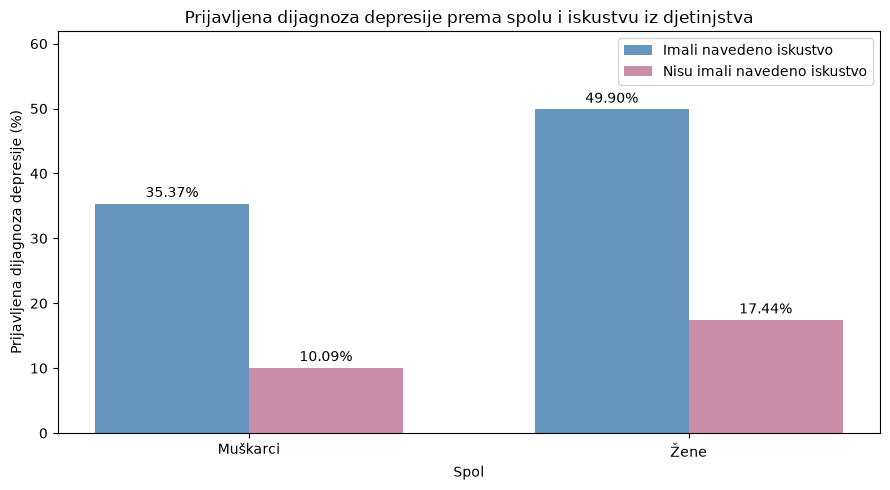

In [42]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

analiza.grafikon_viserazinske_analize(
    rezultati_spol,
    "grafikon_viserazinska_analiza.png"
)



Kod oba spola prijavljena dijagnoza depresije češća je među ispitanicima koji su tokom djetinjstva živjeli s osobom koja je imala mentalne poteškoće.

Kod muškaraca postoci iznose 35,37% i 10,09%, dok kod žena iznose 49,90% i 17,44%, zavisno od prisustva navedenog iskustva.

Razlika između grupa veća je kod žena, ali rezultati ne dokazuju uzročno-posljedičnu povezanost.



## 5. Deskriptivna analiza numeričkih varijabli

### 5.1. Pregled numeričkih varijabli

Prije izračunavanja deskriptivnih pokazatelja provjeravam numeričke varijable, broj popunjenih vrijednosti i njihove raspone. Posebnu pažnju posvećujem kodovima odgovora i mjernim jedinicama.


In [43]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

pregled_numerickih = analiza.pregled_numerickih_varijabli(
    df,
    klasifikacija
)

print("Broj numeričkih varijabli:", len(pregled_numerickih))

print("\nRaspodjela prema mjernoj ljestvici:")
display(
    pregled_numerickih["Mjerna ljestvica"].value_counts()
)

print("\nPregled svih numeričkih varijabli:")
display(pregled_numerickih)

pregled_numerickih.to_csv(
    "pregled_numerickih_varijabli.csv",
    index=False,
    encoding="utf-8-sig"
)


Broj numeričkih varijabli: 44

Raspodjela prema mjernoj ljestvici:


Mjerna ljestvica
Kvantitativne – diskretne       29
Kvantitativne – kontinuirane    15
Name: count, dtype: int64


Pregled svih numeričkih varijabli:


,Varijabla,Opis (Codebook),Mjerna ljestvica,Broj popunjenih,Broj jedinstvenih vrijednosti,Minimum,Maksimum
0,NUMADULT,Number of Adults in Household,Kvantitativne – diskretne,124742,15,1.000000e+00,18.000000
1,NUMMEN,Number of Adult men in Household,Kvantitativne – diskretne,110422,10,5.397605e-79,18.000000
2,NUMWOMEN,Number of Adult women in Household,Kvantitativne – diskretne,110422,14,5.397605e-79,18.000000
3,HHADULT,Number of Adults in Household,Kvantitativne – diskretne,277205,33,1.000000e+00,99.000000
4,PHYSHLTH,Number of Days Physical Health Not Good,Kvantitativne – diskretne,401953,33,1.000000e+00,99.000000
5,MENTHLTH,Number of Days Mental Health Not Good,Kvantitativne – diskretne,401953,33,1.000000e+00,99.000000
6,POORHLTH,Poor Physical or Mental Health,Kvantitativne – diskretne,201615,33,1.000000e+00,99.000000
7,SLEPTIM1,How Much Time Do You Sleep,Kvantitativne – diskretne,401955,26,1.000000e+00,99.000000
8,DIABAGE3,Age When Told Had Diabetes,Kvantitativne – diskretne,52094,96,1.000000e+00,99.000000
9,NUMPHON3,Residential Phones,Kvantitativne – diskretne,30250,9,1.000000e+00,9.000000



#### Provjera posebnih kodova kod numeričkih varijabli

Prije računanja deskriptivnih pokazatelja provjeravam posebne kodove odgovora kod odabranih numeričkih varijabli. Dodatno provjeravam neuobičajeno male vrijednosti koje se pojavljuju kod pojedinih varijabli.


In [44]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

provjera_kodova = analiza.provjera_numerickih_kodova(df)

display(provjera_kodova)

provjera_kodova.to_csv(
    "provjera_numerickih_kodova.csv",
    index=False,
    encoding="utf-8-sig"
)


,Varijabla,Vrijednost,Frekvencija (n),Postotak popunjenih (%)
0,SLEPTIM1,77,4110,1.02
1,SLEPTIM1,99,581,0.14
2,MENTHLTH,77,5833,1.45
3,MENTHLTH,88,255707,63.62
4,MENTHLTH,99,2091,0.52
5,PHYSHLTH,77,7095,1.77
6,PHYSHLTH,88,278671,69.33
7,PHYSHLTH,99,1591,0.40
8,POORHLTH,77,4178,2.07
9,POORHLTH,88,111321,55.21



#### Provjera vrijednosti bliskih nuli

Kod pojedinih numeričkih varijabli pojavljuju se veoma male pozitivne vrijednosti. Provjeravam njihovu zastupljenost i upoređujem ih s ostalim vrijednostima kako bih utvrdila zahtijevaju li posebno postupanje.


In [45]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

provjera_nule = analiza.provjera_vrijednosti_bliskih_nuli(
    df,
    ["NUMMEN", "NUMWOMEN", "DROCDY3_"]
)

display(provjera_nule)

provjera_nule.to_csv(
    "provjera_vrijednosti_bliskih_nuli.csv",
    index=False,
    encoding="utf-8-sig"
)


,Varijabla,Tačne nule,Vrijednosti između 0 i 0.000001,Najmanja pozitivna vrijednost,Najmanja vrijednost iznad 0.000001
0,NUMMEN,0,31022,5.397605e-79,1.0
1,NUMWOMEN,0,13886,5.397605e-79,1.0
2,DROCDY3_,0,183618,5.397605e-79,3.0



#### Dodatna provjera najmanjih numeričkih vrijednosti

Provjeravam najmanje vrijednosti i njihove frekvencije kod varijabli NUMMEN, NUMWOMEN i DROCDY3_, kako bih bolje razumjela neuobičajeno male zapise prije statističke analize.


In [46]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

najmanje_vrijednosti = analiza.pregled_najmanjih_vrijednosti(
    df,
    ["NUMMEN", "NUMWOMEN", "DROCDY3_"]
)

for naziv, rezultat in najmanje_vrijednosti.items():
    print(f"\nVarijabla: {naziv}")
    display(rezultat.to_frame("Frekvencija (n)"))



Varijabla: NUMMEN


,Frekvencija (n)
NUMMEN,
5.397605e-79,31022
1.000000e+00,69875
2.000000e+00,7974
3.000000e+00,1327
4.000000e+00,181
5.000000e+00,29
6.000000e+00,8
7.000000e+00,3
8.000000e+00,2



Varijabla: NUMWOMEN


,Frekvencija (n)
NUMWOMEN,
5.397605e-79,13886
1.000000e+00,85376
2.000000e+00,9577
3.000000e+00,1340
4.000000e+00,183
5.000000e+00,41
6.000000e+00,7
7.000000e+00,2
8.000000e+00,1



Varijabla: DROCDY3_


,Frekvencija (n)
DROCDY3_,
5.397605e-79,183618
3.000000e+00,27715
7.000000e+00,21224
1.000000e+01,11984
1.300000e+01,10021
1.400000e+01,16147
1.700000e+01,10038
2.000000e+01,3679
2.300000e+01,2622



### 5.2. Deskriptivni statistički pokazatelji numeričkih varijabli

Za početak računam deskriptivne pokazatelje odabranih numeričkih varijabli. Prije izračuna pripremam privremenu kopiju podataka, u kojoj posebne kodove odgovora i mjerne jedinice prilagođavam njihovom stvarnom značenju.


In [48]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

numericki_podaci = analiza.priprema_numerickih_podataka(df)

statistika = analiza.deskriptivna_statistika(
    numericki_podaci
)

print("Broj analiziranih numeričkih varijabli:", len(statistika))

display(statistika)

statistika.to_csv(
    "deskriptivna_statistika_odabranih_varijabli.csv",
    index=False,
    encoding="utf-8-sig"
)


Broj analiziranih numeričkih varijabli: 7


,Varijabla,N,Minimum,Maksimum,Sredina,Standardna devijacija,CV (%),Medijan,Q1,Q3,IQR,Asimetričnost,Zaobljenost,Skraćena sredina (5%)
0,_AGE80,401958,18.00,80.00,54.43,17.67,32.46,57.00,40.00,69.00,29.00,-0.32,-0.98,54.90
1,SLEPTIM1,397264,1.00,24.00,7.10,1.47,20.69,7.00,6.00,8.00,2.00,0.76,8.57,7.09
2,MENTHLTH,394029,0.00,30.00,3.92,8.05,205.43,0.00,0.00,3.00,3.00,2.32,4.30,2.68
3,PHYSHLTH,393267,0.00,30.00,3.46,8.08,233.74,0.00,0.00,2.00,2.00,2.55,5.22,2.18
4,HTM4,380227,91.00,241.00,170.12,10.72,6.30,170.00,163.00,178.00,15.00,0.01,0.21,170.06
5,WTKG3,367010,22.68,290.30,82.32,20.99,25.50,79.38,68.04,92.99,24.95,1.04,2.56,81.14
6,_BMI5,360601,12.02,98.43,28.31,6.38,22.54,27.32,23.99,31.38,7.39,1.36,4.19,27.88



Analizirano je sedam odabranih numeričkih varijabli. Prosječna dob ispitanika iznosi 54,43 godine, a prosječno trajanje spavanja 7,10 sati.

Kod MENTHLTH i PHYSHLTH medijan iznosi 0, dok su aritmetičke sredine 3,92 i 3,46. Obje varijable imaju izraženu pozitivnu asimetričnost.

Skraćene sredine iznose 2,68 i 2,18, što pokazuje da više vrijednosti utiču na obične sredine. Kod visine je razlika između obične i skraćene sredine veoma mala.



#### Pregled preostalih numeričkih varijabli

Prije izračunavanja deskriptivnih pokazatelja za preostale numeričke varijable provjeravam njihove raspone, broj dostupnih vrijednosti i najčešće zabilježene odgovore. Posebne kodove i mjerne jedinice potrebno je protumačiti prema Codebooku.


In [49]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

obradjene_varijable = [
    "_AGE80", "SLEPTIM1", "MENTHLTH",
    "PHYSHLTH", "HTM4", "WTKG3", "_BMI5",
    "WORKCFS"
]

pregled_preostalih = analiza.pregled_preostalih_numerickih(
    df,
    pregled_numerickih,
    obradjene_varijable
)

print("Broj preostalih numeričkih varijabli:", len(pregled_preostalih))

display(pregled_preostalih)

pregled_preostalih.to_csv(
    "pregled_preostalih_numerickih.csv",
    index=False,
    encoding="utf-8-sig"
)


Broj preostalih numeričkih varijabli: 36


,Varijabla,Opis,Mjerna ljestvica,Broj popunjenih,Broj jedinstvenih vrijednosti,Minimum,Maksimum,Najčešće vrijednosti
0,NUMADULT,Number of Adults in Household,Kvantitativne – diskretne,124742,15,1.000000e+00,18.000000,"nan: 277216, 2.0: 58784, 1.0: 51455, 3.0: 1015..."
1,NUMMEN,Number of Adult men in Household,Kvantitativne – diskretne,110422,10,5.397605e-79,18.000000,"nan: 291536, 1.0: 69875, 5.397605346934028e-79..."
2,NUMWOMEN,Number of Adult women in Household,Kvantitativne – diskretne,110422,14,5.397605e-79,18.000000,"nan: 291536, 1.0: 85376, 5.397605346934028e-79..."
3,HHADULT,Number of Adults in Household,Kvantitativne – diskretne,277205,33,1.000000e+00,99.000000,"2.0: 137783, nan: 124753, 1.0: 65688, 3.0: 425..."
4,POORHLTH,Poor Physical or Mental Health,Kvantitativne – diskretne,201615,33,1.000000e+00,99.000000,"nan: 200343, 88.0: 111321, 30.0: 15239, 2.0: 1..."
5,DIABAGE3,Age When Told Had Diabetes,Kvantitativne – diskretne,52094,96,1.000000e+00,99.000000,"nan: 349864, 50.0: 4770, 60.0: 3680, 98.0: 317..."
6,NUMPHON3,Residential Phones,Kvantitativne – diskretne,30250,9,1.000000e+00,9.000000,"nan: 371708, 1.0: 20334, 2.0: 6505, 3.0: 1784,..."
7,CHILDREN,Number of Children in Household,Kvantitativne – diskretne,397191,27,1.000000e+00,99.000000,"88.0: 289105, 1.0: 43345, 2.0: 36227, 3.0: 158..."
8,WEIGHT2,Reported Weight in Pounds,Kvantitativne – kontinuirane,392106,574,5.000000e+01,9999.000000,"200.0: 19745, 180.0: 18493, 9999.0: 17968, 150..."
9,HEIGHT3,Reported Height in Feet and Inches,Kvantitativne – kontinuirane,391134,147,2.040000e+02,9999.000000,"506.0: 33784, 504.0: 33015, 507.0: 30496, 505...."



#### Provjera posebnih kodova preostalih numeričkih varijabli

Na osnovu Codebook dokumentacije provjeravam zastupljenost posebnih kodova kod odabranih numeričkih varijabli. Ova provjera pomaže mi da utvrdim koje vrijednosti predstavljaju stvarne količine, a koje zahtijevaju drugačije tumačenje.


In [50]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

posebni_numericki_kodovi = analiza.pregled_posebnih_numerickih_kodova(df)

display(posebni_numericki_kodovi)

posebni_numericki_kodovi.to_csv(
    "posebni_numericki_kodovi.csv",
    index=False,
    encoding="utf-8-sig"
)


,Varijabla,Značenje,Kodovi,Frekvencija (n),Postotak popunjenih (%)
0,CHILDREN,Nema djece,88,289105,72.79
1,CHILDREN,Odbijen odgovor,99,3651,0.92
2,DIABAGE3,Ne znam,98,3178,6.10
3,DIABAGE3,Odbijen odgovor,99,251,0.48
4,ALCDAY5,Ne znam,777,3598,0.94
5,ALCDAY5,Nije konzumirao alkohol,888,183618,48.19
6,ALCDAY5,Odbijen odgovor,999,2250,0.59
7,DROCDY3_,Nepoznat ili nedostajući podatak,900,26775,6.66
8,_DRNKWK1,Nepoznat ili nedostajući podatak,99900,30691,7.64



#### Deskriptivna analiza dodatnih numeričkih varijabli

Nakon provjere posebnih kodova pripremam šest numeričkih varijabli i za njih računam deskriptivne statističke pokazatelje. Izmjene se provode na kopiji podataka.


In [51]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

dodatni_numericki = analiza.priprema_preostalih_numerickih(df)

statistika_dodatnih = analiza.deskriptivna_statistika(
    dodatni_numericki
)

print("Broj analiziranih varijabli:", len(statistika_dodatnih))

display(statistika_dodatnih)

statistika_dodatnih.to_csv(
    "deskriptivna_statistika_dodatnih_varijabli.csv",
    index=False,
    encoding="utf-8-sig"
)


Broj analiziranih varijabli: 6


,Varijabla,N,Minimum,Maksimum,Sredina,Standardna devijacija,CV (%),Medijan,Q1,Q3,IQR,Asimetričnost,Zaobljenost,Skraćena sredina (5%)
0,NUMADULT,124742,1.0,18.0,1.75,0.82,46.59,2.0,1.0,2.0,1.0,2.11,16.70,1.67
1,NUMMEN,110422,0.0,18.0,0.82,0.63,76.43,1.0,0.0,1.0,1.0,0.93,7.99,0.78
2,NUMWOMEN,110422,0.0,18.0,0.99,0.55,55.21,1.0,1.0,1.0,0.0,2.36,45.94,0.97
3,HHADULT,275337,1.0,54.0,2.19,1.12,50.97,2.0,2.0,3.0,1.0,3.53,66.61,2.09
4,CHILDREN,393540,0.0,82.0,0.52,1.11,213.03,0.0,0.0,1.0,1.0,10.61,610.61,0.37
5,DIABAGE3,48665,1.0,94.0,50.00,14.82,29.65,50.0,40.0,60.0,20.0,-0.48,0.24,50.47



Analizirano je šest dodatnih numeričkih varijabli. Prosječan broj odraslih članova domaćinstva iznosi 1,75 kod NUMADULT i 2,19 kod HHADULT.

Kod CHILDREN medijan iznosi 0, a raspodjela je izrazito pozitivno asimetrična.

Prosječna dob pri dijagnozi dijabetesa iznosi 50 godina, uz medijan od 50 godina. Obična i skraćena sredina su gotovo jednake.



#### Deskriptivna analiza varijabli povezanih s konzumiranjem alkohola

Pripremam četiri numeričke varijable povezane s konzumiranjem alkohola. Posebne kodove odgovora prilagođavam njihovom značenju, a učestalost konzumiranja izražavam na zajedničkoj vremenskoj osnovi od 30 dana.


In [56]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

podaci_alkohol = analiza.priprema_varijabli_alkohol(df)

statistika_alkohol = analiza.deskriptivna_statistika(
    podaci_alkohol
)

print("Broj analiziranih varijabli:", len(statistika_alkohol))

display(statistika_alkohol)

statistika_alkohol.to_csv(
    "deskriptivna_statistika_alkohol.csv",
    index=False,
    encoding="utf-8-sig"
)


Broj analiziranih varijabli: 4


,Varijabla,N,Minimum,Maksimum,Sredina,Standardna devijacija,CV (%),Medijan,Q1,Q3,IQR,Asimetričnost,Zaobljenost,Skraćena sredina (5%)
0,ALCDAY5,375183,0.0,30.0,5.17,8.57,165.69,1.0,0.0,6.0,6.0,1.86,2.35,4.08
1,AVEDRNK3,187649,0.0,76.0,2.24,2.47,110.18,2.0,1.0,3.0,2.0,9.14,168.51,1.91
2,DRNK3GE5,187041,0.0,76.0,1.29,4.13,320.27,0.0,0.0,1.0,1.0,5.44,35.41,0.54
3,MAXDRNKS,182755,1.0,76.0,3.31,3.42,103.20,2.0,1.0,4.0,3.0,5.10,55.66,2.84



Analizirane su četiri varijable povezane s konzumiranjem alkohola. Prosječan broj dana konzumiranja alkohola u posljednjih 30 dana iznosi 5,17, dok je medijan jedan dan.

Kod DRNK3GE5 medijan iznosi 0, što znači da najmanje polovina ispitanika s valjanim odgovorom nije prijavila intenzivno pijenje.

Sve četiri raspodjele imaju pozitivnu asimetričnost, a skraćene sredine su niže od običnih.



#### Deskriptivna analiza zdravstvenog stanja i padova

Analiziram broj dana lošeg zdravstvenog stanja te učestalost padova i povreda. Prije izračuna prilagođavam posebne kodove odgovora, pri čemu se vrijednost 88 tumači kao nula, a nepoznati i odbijeni odgovori isključuju.


In [60]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

podaci_zdravlje_padovi = analiza.priprema_varijabli_zdravlje_padovi(df)

statistika_zdravlje_padovi = analiza.deskriptivna_statistika(
    podaci_zdravlje_padovi
)

print("Broj analiziranih varijabli:", len(statistika_zdravlje_padovi))

display(statistika_zdravlje_padovi)

statistika_zdravlje_padovi.to_csv(
    "deskriptivna_statistika_zdravlje_padovi.csv",
    index=False,
    encoding="utf-8-sig"
)


Broj analiziranih varijabli: 3


,Varijabla,N,Minimum,Maksimum,Sredina,Standardna devijacija,CV (%),Medijan,Q1,Q3,IQR,Asimetričnost,Zaobljenost,Skraćena sredina (5%)
0,POORHLTH,196348,0.0,30.0,5.09,9.00,176.72,0.0,0.0,5.0,5.0,1.87,2.21,3.99
1,FALL12MN,260678,0.0,76.0,0.79,3.36,427.15,0.0,0.0,1.0,1.0,14.41,274.13,0.36
2,FALLINJ4,68098,0.0,76.0,0.73,2.74,377.64,0.0,0.0,1.0,1.0,18.18,441.09,0.42



Kod POORHLTH prosječan broj dana u kojima je loše zdravlje ometalo svakodnevne aktivnosti iznosi 5,09, dok je medijan 0.

Kod FALL12MN i FALLINJ4 prosjeci iznose 0,79 i 0,73, a medijan je također 0. Sve tri raspodjele su pozitivno asimetrične, posebno varijable povezane s padovima.



#### Deskriptivna analiza varijabli povezanih s kontrolom dijabetesa

Analiziram četiri varijable povezane s kontrolom dijabetesa. Prije izračuna prilagođavam posebne kodove i učestalost mjerenja svodim na zajedničku vremensku osnovu. Izmjene radim na kopiji podataka.


In [61]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

podaci_dijabetes = analiza.priprema_varijabli_dijabetes(df)

statistika_dijabetes = analiza.deskriptivna_statistika(
    podaci_dijabetes
)

print("Broj analiziranih varijabli:", len(statistika_dijabetes))

display(statistika_dijabetes)

statistika_dijabetes.to_csv(
    "deskriptivna_statistika_dijabetes.csv",
    index=False,
    encoding="utf-8-sig"
)


Broj analiziranih varijabli: 4


,Varijabla,N,Minimum,Maksimum,Sredina,Standardna devijacija,CV (%),Medijan,Q1,Q3,IQR,Asimetričnost,Zaobljenost,Skraćena sredina (5%)
0,BLDSUGAR,12707,0.0,2970.0,48.82,181.96,372.69,30.0,4.29,60.0,55.71,14.82,231.50,33.15
1,FEETCHK3,12548,0.0,2970.0,29.39,128.73,438.00,30.0,4.29,30.0,25.71,21.50,482.82,21.27
2,DOCTDIAB,12661,0.0,76.0,3.32,5.50,165.55,2.0,1.00,4.0,3.00,9.06,105.40,2.63
3,CHKHEMO3,12337,0.0,76.0,2.86,4.36,152.33,2.0,1.00,4.0,3.00,12.08,183.47,2.45



Analizirane su četiri varijable povezane s kontrolom dijabetesa. Prosječan broj mjerenja šećera u krvi iznosi 48,82 mjesečno, a pregleda stopala 29,39.

Prosječan broj posjeta zdravstvenim radnicima iznosi 3,32 godišnje, dok je prosjek provjera HbA1c 2,86.

Sve četiri varijable imaju pozitivnu asimetričnost. Posebno visoke vrijednosti kod BLDSUGAR i FEETCHK3 potrebno je dodatno provjeriti u analizi ekstremnih vrijednosti.



#### Deskriptivna analiza pušenja i konzumiranja marihuane

Analiziram četiri numeričke varijable povezane s pušenjem i konzumiranjem marihuane. Prije izračuna posebne kodove prilagođavam njihovom značenju, bez izmjene izvornog dataseta.


In [63]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

podaci_pusenje = analiza.priprema_varijabli_pusenje(df)

statistika_pusenje = analiza.deskriptivna_statistika(
    podaci_pusenje
)

display(statistika_pusenje)

statistika_pusenje.to_csv(
    "deskriptivna_statistika_pusenje.csv",
    index=False,
    encoding="utf-8-sig"
)


,Varijabla,N,Minimum,Maksimum,Sredina,Standardna devijacija,CV (%),Medijan,Q1,Q3,IQR,Asimetričnost,Zaobljenost,Skraćena sredina (5%)
0,MARIJAN1,129223,0.0,30.0,1.45,5.91,407.36,0.0,0.0,0.0,0.0,4.29,17.10,0.16
1,LCSFIRST,13192,1.0,77.0,17.56,4.80,27.33,17.0,15.0,19.0,4.0,2.77,17.82,17.18
2,LCSLAST,12828,1.0,100.0,42.15,16.01,37.98,40.0,29.0,55.0,26.0,0.42,-0.71,41.62
3,LCSNUMCG,13015,1.0,220.0,15.86,12.47,78.63,15.0,8.0,20.0,12.0,2.50,15.38,14.66



Nakon ispravke posebnih kodova, prosječna dob početka redovnog pušenja iznosi 17,56 godina, a prosječan broj cigareta dnevno 15,86.

Kod varijable MARIJAN1 medijan iznosi 0, uz izraženu pozitivnu asimetričnost. To pokazuje da većina ispitanika nije prijavila konzumiranje marihuane u posljednjih 30 dana.



#### Završna analiza odabranih numeričkih varijabli

Za završetak deskriptivne analize obrađujem još tri numeričke varijable. Posebne kodove prilagođavam njihovom značenju i računam statističke pokazatelje.


In [64]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

zavrsni_podaci = analiza.priprema_zavrsnih_numerickih(df)

zavrsna_statistika = analiza.deskriptivna_statistika(
    zavrsni_podaci
)

display(zavrsna_statistika)

zavrsna_statistika.to_csv(
    "zavrsna_numericka_statistika.csv",
    index=False,
    encoding="utf-8-sig"
)


,Varijabla,N,Minimum,Maksimum,Sredina,Standardna devijacija,CV (%),Medijan,Q1,Q3,IQR,Asimetričnost,Zaobljenost,Skraćena sredina (5%)
0,NUMPHON3,29445,0.0,6.0,1.39,0.73,52.95,1.0,1.0,2.0,1.0,2.16,6.93,1.30
1,FEETCHK,12615,0.0,76.0,2.53,5.89,233.03,1.0,0.0,3.0,3.0,9.23,101.79,1.77
2,CNCRAGE,21431,1.0,97.0,55.39,15.69,28.33,58.0,45.0,67.0,22.0,-0.54,0.06,55.92



Prosječan broj kućnih telefonskih linija iznosi 1,39, a broj pregleda stopala kod zdravstvenog radnika 2,53 godišnje.

Kod FEETCHK prisutna je izražena pozitivna asimetričnost. Prosječna dob pri dijagnozi raka iznosi 55,39 godina, uz medijan od 58 godina.



#### Pregled preostalih numeričkih varijabli

Provjeravam preostale numeričke varijable kako bih utvrdila koje vrijednosti treba dodatno prilagoditi, a za koje se mogu izračunati deskriptivni statistički pokazatelji.


In [72]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

preostale_varijable = analiza.pregled_preostalih_varijabli(df)

display(preostale_varijable)


,Varijabla,Broj popunjenih,Broj jedinstvenih,Minimum,Maksimum
0,WEIGHT2,392106,574,5.000000e+01,9999.000000
1,HEIGHT3,391134,147,2.040000e+02,9999.000000
2,HTIN4,378150,55,3.600000e+01,95.000000
3,DROCDY3_,401958,36,5.397605e-79,900.000000
4,_DRNKWK1,401958,276,5.397605e-79,99900.000000
5,_STRWT,401958,1601,3.380387e-01,1540.115714
6,_RAWRAKE,401958,12,3.333333e-01,5.000000
7,_WT2RAKE,401958,6255,1.690193e-01,5338.969306
8,_CLLCPWT,54954,21130,7.655604e-01,102357.725796
9,_DUALCOR,177721,106,3.694935e-02,0.963051


In [ ]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

preostali_podaci = analiza.priprema_dodatnih_12_varijabli(df)

preostala_statistika = analiza.deskriptivna_statistika(
    preostali_podaci
)

display(preostala_statistika)

preostala_statistika.to_csv(
    "preostala_numericka_statistika.csv",
    index=False,
    encoding="utf-8-sig"
)


,Varijabla,N,Minimum,Maksimum,Sredina,Standardna devijacija,CV (%),Medijan,Q1,Q3,IQR,Asimetričnost,Zaobljenost,Skraćena sredina (5%)
0,WEIGHT2,367022,22.68,352.00,82.33,21.04,25.56,79.38,68.04,92.99,24.95,1.09,3.10,81.14
1,HEIGHT3,380229,90.00,238.76,170.12,10.70,6.29,170.18,162.56,177.80,15.24,0.03,0.21,170.05
2,HTIN4,378150,36.00,95.00,66.99,4.19,6.25,67.00,64.00,70.00,6.00,0.08,-0.08,66.96
3,DROCDY3_,375183,0.00,1.00,0.17,0.29,165.82,0.03,0.00,0.20,0.20,1.86,2.34,0.14
4,_DRNKWK1,371267,0.00,532.00,3.01,9.32,309.73,0.23,0.00,2.80,2.80,17.55,630.49,1.75
5,_STRWT,401958,0.34,1540.12,81.71,167.00,204.38,41.54,15.78,81.67,65.90,6.16,44.23,55.92
6,_RAWRAKE,401958,0.33,5.00,1.21,0.55,45.06,1.00,1.00,1.00,0.00,3.03,11.39,1.13
7,_WT2RAKE,401958,0.17,5338.97,88.73,175.53,197.84,45.81,18.74,87.29,68.55,6.39,55.89,61.37
8,_CLLCPWT,54954,0.77,102357.73,921.95,2372.58,257.34,316.39,131.50,753.07,621.57,8.51,131.81,540.77
9,_DUALCOR,177721,0.04,0.96,0.53,0.13,25.44,0.52,0.44,0.61,0.17,0.07,-0.10,0.53



Za 12 preostalih numeričkih varijabli izračunati su deskriptivni statistički pokazatelji. Posebni kodovi i mjerne jedinice prethodno su prilagođeni njihovom značenju.

Sedam varijabli predstavljaju tehničke težinske faktore, dok WORKCFS nema nijednu popunjenu vrijednost.

Time su pregledane sve 44 numeričke varijable.



Raspodjela dobi pokazuje veću zastupljenost starijih ispitanika, uz izraženu koncentraciju na vrijednosti 80 koja obuhvata i starije osobe.

Kod MENTHLTH najveći broj ispitanika ima vrijednost 0, dok manji broj prijavljuje više dana lošeg mentalnog zdravlja. Raspodjela je izrazito pozitivno asimetrična i odstupa od normalne krivulje.



## 6. Ekstremne vrijednosti i provjera raspodjela

### 6.1. Otkrivanje ekstremnih vrijednosti primjenom IQR pravila

Za varijable MENTHLTH i _BMI5 primjenjujem IQR pravilo i računam broj i postotak potencijalnih ekstremnih vrijednosti. Rezultate dodatno prikazujem box-plot grafikonima.


,Varijabla,N,Q1,Q3,IQR,Donja granica,Gornja granica,Broj ekstrema,Postotak ekstrema (%)
0,MENTHLTH,394029,0.00,3.00,3.00,-4.5,7.50,63720,16.17
1,_BMI5,360601,23.99,31.38,7.39,12.9,42.46,11778,3.27


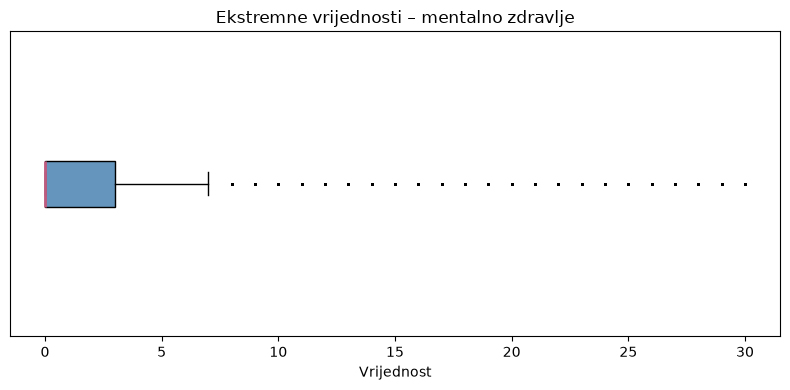

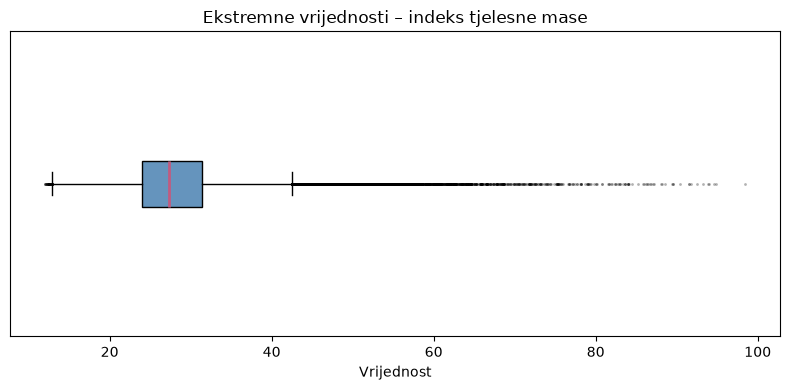

In [82]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

ekstremi = analiza.analiza_ekstremnih_vrijednosti(
    numericki_podaci,
    ["MENTHLTH", "_BMI5"]
)

display(ekstremi)

ekstremi.to_csv(
    "ekstremne_vrijednosti.csv",
    index=False,
    encoding="utf-8-sig"
)

analiza.boxplot_numerickih(
    numericki_podaci,
    [
        (
            "MENTHLTH",
            "Ekstremne vrijednosti – mentalno zdravlje",
            "boxplot_mentalno_zdravlje.png"
        ),
        (
            "_BMI5",
            "Ekstremne vrijednosti – indeks tjelesne mase",
            "boxplot_bmi.png"
        )
    ]
)



Primjenom IQR pravila označeno je 63.720 potencijalnih ekstremnih vrijednosti kod MENTHLTH (16,17%) i 11.778 kod _BMI5 (3,27%).

Box-plotovi pokazuju izraženije desne repove raspodjela. Označene vrijednosti nisu automatski uklonjene jer mogu predstavljati stvarne odgovore ispitanika.



### 6.2. Provjera odstupanja od normalne raspodjele

Na osnovu histograma, box-plotova i statističkih pokazatelja uočavam da MENTHLTH i _BMI5 odstupaju od normalne raspodjele.

MENTHLTH ima izraženiju pozitivnu asimetričnost (2,32) i zaobljenost (4,30), dok su kod _BMI5 ove vrijednosti 1,36 i 4,19. Obje raspodjele imaju duži desni rep, posebno MENTHLTH.



## 7. Odnosi među varijablama i višerazinska analiza

### 7.1. Povezanost dvije numeričke varijable

Raspršenim dijagramom prikazujem odnos dobi ispitanika i indeksa tjelesne mase. Izračunavam i Pearsonov koeficijent korelacije kako bih procijenila smjer i jačinu njihove linearne povezanosti.


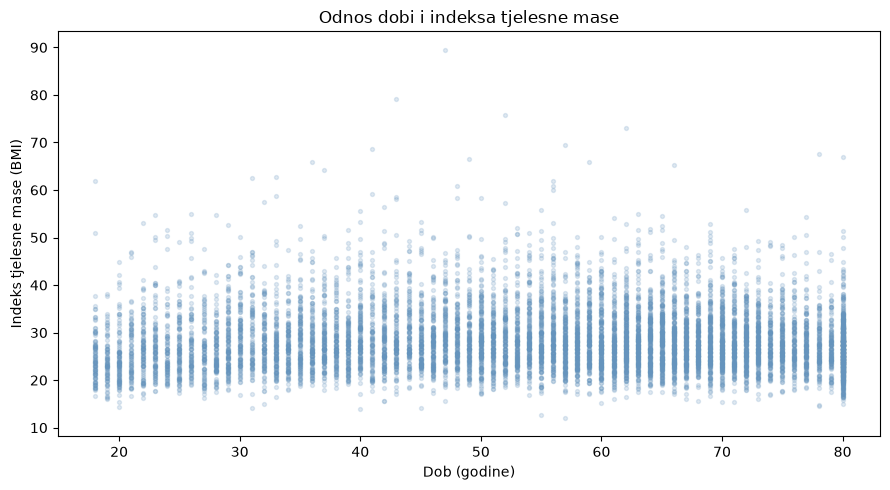

Broj uključenih zapisa: 360601
Pearsonova korelacija: -0.004


In [84]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

broj, korelacija = analiza.rasprseni_dijagram(
    numericki_podaci,
    "_AGE80",
    "_BMI5",
    "grafikon_dob_bmi.png"
)

print("Broj uključenih zapisa:", broj)
print("Pearsonova korelacija:", round(korelacija, 3))



Raspršeni dijagram prikazuje odnos dobi i BMI-ja na osnovu 360.601 zapisa. Pearsonov koeficijent korelacije iznosi -0,004, što pokazuje da između ovih varijabli praktično nema linearne povezanosti.



### 7.2. Odnos numeričke i kategorijske varijable

Upoređujem broj dana lošeg mentalnog zdravlja između ispitanika koji su prijavili dijagnozu depresije i onih koji nisu.


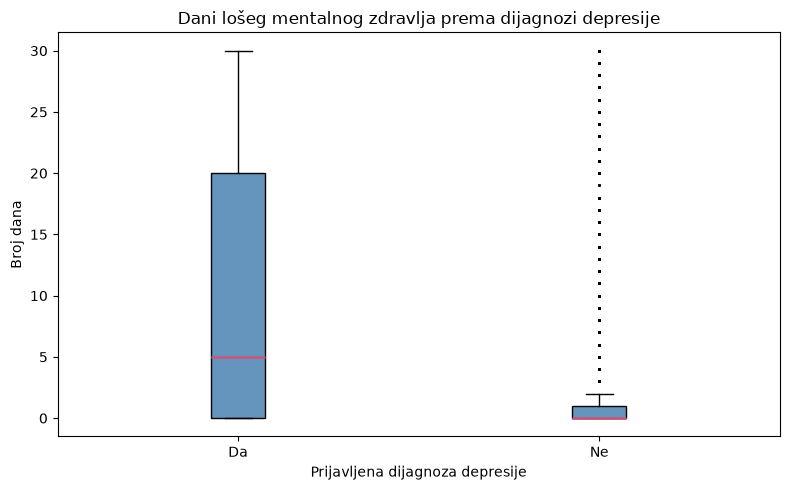

,count,mean,median
ADDEPEV3,,,
Da,73734,10.77,5.0
Ne,318534,2.31,0.0


In [ ]:

podaci_poredjenje = numericki_podaci[["MENTHLTH"]].copy()
podaci_poredjenje["ADDEPEV3"] = df["ADDEPEV3"]

statistika_grupa = analiza.boxplot_po_kategoriji(
    podaci_poredjenje,
    "MENTHLTH",
    "ADDEPEV3",
    "grafikon_mentalno_zdravlje_depresija.png"
)

display(statistika_grupa)



Ispitanici s prijavljenom dijagnozom depresije imaju prosječno 10,77 dana lošeg mentalnog zdravlja, uz medijan od 5 dana.

Kod ispitanika bez prijavljene dijagnoze prosjek iznosi 2,31 dan, a medijan 0.

Razlika je jasno vidljiva na box-plotu, ali ne dokazuje uzročno-posljedičnu povezanost.



### 7.3. Odnos kategorijskih varijabli i višerazinska analiza

Odnos između ACEDEPRS i ADDEPEV3 već je analiziran u poglavljima 4.2. i 4.3., uključujući poređenje prema spolu.

Rezultati pokazuju veću zastupljenost prijavljene dijagnoze depresije među ispitanicima s navedenim iskustvom iz djetinjstva, kod oba spola. Razlika između posmatranih grupa veća je kod žena.



## 8. Korelacijska analiza – obavezna heatmapa

Za šest odabranih numeričkih varijabli računam Spearmanovu korelacijsku matricu. Rezultate prikazujem heatmapom i izdvajam tri para varijabli s najvećom apsolutnom korelacijom.


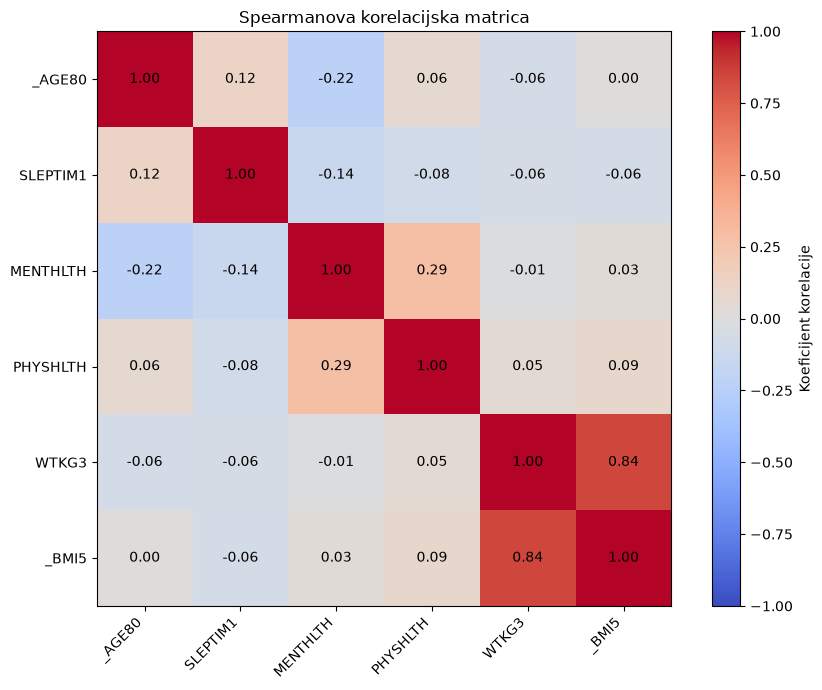

Korelacijska matrica:


,_AGE80,SLEPTIM1,MENTHLTH,PHYSHLTH,WTKG3,_BMI5
_AGE80,1.000,0.119,-0.221,0.063,-0.064,0.001
SLEPTIM1,0.119,1.000,-0.135,-0.083,-0.062,-0.063
MENTHLTH,-0.221,-0.135,1.000,0.285,-0.011,0.025
PHYSHLTH,0.063,-0.083,0.285,1.000,0.053,0.092
WTKG3,-0.064,-0.062,-0.011,0.053,1.000,0.843
_BMI5,0.001,-0.063,0.025,0.092,0.843,1.000


Tri para s najvećom korelacijom:


,Varijabla 1,Varijabla 2,Korelacija
14,WTKG3,_BMI5,0.843
9,MENTHLTH,PHYSHLTH,0.285
1,_AGE80,MENTHLTH,-0.221


In [ ]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

matrica, najjaci_parovi = analiza.korelacijska_analiza(
    numericki_podaci
)

print("Korelacijska matrica:")
display(matrica)

print("Tri para s najvećom korelacijom:")
display(najjaci_parovi)

matrica.to_csv(
    "korelacijska_matrica.csv",
    encoding="utf-8-sig"
)

najjaci_parovi.to_csv(
    "najjaci_korelacijski_parovi.csv",
    index=False,
    encoding="utf-8-sig"
)



Najveća korelacija zabilježena je između WTKG3 i _BMI5 (0,843), što je očekivano jer BMI zavisi od tjelesne mase.

MENTHLTH i PHYSHLTH imaju slabu pozitivnu korelaciju (0,285), dok između _AGE80 i MENTHLTH postoji slaba negativna korelacija (-0,221).

Korelacija pokazuje povezanost između varijabli, ali ne dokazuje uzročnost.



## 9. Prijedlog postupanja s nedostajućim i problematičnim podacima

### 9.1. Prijedlozi za obradu nedostajućih vrijednosti

Za odabrane varijable računam broj i postotak problematičnih zapisa. Također upoređujem medijan BMI-ja na nivou cijelog skupa i prema spolu kako bih procijenila mogućnosti nadomještanja nedostajućih vrijednosti.


In [ ]:

import importlib
import io
from contextlib import redirect_stdout
import analiza

with redirect_stdout(io.StringIO()):
    importlib.reload(analiza)

pregled_prijedloga, medijani_bmi, medijan_bmi = (
    analiza.prijedlozi_nedostajucih(df, numericki_podaci)
)

print("Pregled problematičnih vrijednosti:")
display(pregled_prijedloga)

print("Medijan BMI-ja za cijeli skup:", round(medijan_bmi, 2))

print("Medijan BMI-ja prema spolu:")
display(medijani_bmi)

pregled_prijedloga.to_csv(
    "prijedlozi_nedostajucih.csv",
    index=False,
    encoding="utf-8-sig"
)


KeyboardInterrupt: 


Kod ACEDEPRS utvrđeno je 275.154 zapisa bez valjanog odgovora (68,45%), dok je WORKCFS potpuno prazna varijabla. Kod MENTHLTH razmotreno je nadomještanje medijanom zbog asimetrične raspodjele.

Medijan BMI-ja iznosi 27,32 za cijeli skup, 27,47 za muškarce i 26,63 za žene. Nadomještanje unutar grupa moglo bi bolje sačuvati razlike među ispitanicima.

Svi postupci su samo prijedlozi i nisu primijenjeni na izvorne podatke.



## 10. Normalizacija, standardizacija i transformacije

Na osnovu deskriptivne analize razmatram moguće postupke skaliranja i transformacije numeričkih varijabli.

Za _AGE80, WTKG3 i _BMI5 mogla bi se koristiti Z-standardizacija ili min–max normalizacija radi uporedivosti vrijednosti.

Kod MENTHLTH i PHYSHLTH, zbog pozitivne asimetričnosti i prisustva nula, mogla bi se razmotriti transformacija log(1 + x).

Skaliranje mijenja mjerilo vrijednosti, dok transformacija može promijeniti oblik raspodjele. Postupci nisu primijenjeni na izvorni dataset.



## 11. Sažetak nalaza eksploratorne analize

Na osnovu provedene analize izdvojeno je šest najvažnijih nalaza:

1. **Nedostajući podaci:** Kod ACE varijabli nedostaje približno 68% podataka (Tabela 8), zbog čega automatsko nadomještanje nije preporučljivo.

2. **Valjani zapisi:** Za sve posmatrane ACE varijable i ADDEPEV3 dostupno je 117.338 zapisa s valjanim odgovorima (Tabela 11), što omogućava nastavak analize.

3. **Iskustva iz djetinjstva:** Prijavljena depresija zastupljenija je kod ispitanika s iskustvom života s osobom koja je imala mentalne poteškoće (44,41% prema 14,02%; poglavlje 4).

4. **Asimetričnost:** MENTHLTH ima izraženu pozitivnu asimetričnost i 16,17% potencijalnih ekstrema (Grafikon 8 i Tabela 40), pa treba razmotriti robusne postupke.

5. **Prijavljena depresija:** Ispitanici s prijavljenom dijagnozom imaju prosječno 10,77 dana lošeg mentalnog zdravlja, a ostali 2,31 dan (Grafikon 12).

6. **Korelacija:** Najveća Spearmanova korelacija iznosi 0,843 između WTKG3 i _BMI5 (Tabela 41), što ukazuje na moguće preklapanje informacija.

Nalazi predstavljaju osnovu za daljnju obradu podataka. U ovoj fazi nisu provođeni postupci modeliranja niti su mijenjani izvorni podaci.
